# GlucoseNet experiments — hypo-aware CGM forecasting on DiaData (PyTorch)

**Research question.** Standard forecasting models miss most hypoglycaemia. Does
**up-weighting low-glucose errors in the loss** (hypo-weighted loss) reduce missed lows,
and at what cost in overall accuracy and false alarms?

*Round 1 showed the Δ target has no measurable effect, so the proposed method is now
**LSTM + hypo-weighted loss** (level target). The Δ variants stay in the ablation.*

**What this notebook runs**

| Step | What | Horizon |
|---|---|---|
| A | Benchmark: persistence, ridge regression, CNN, LSTM, CNN-BiLSTM-Attention (3 seeds) | 30 min |
| B | Choose the hypo weight **W** on the *validation* set (pre-defined rule) | 30 min |
| C | 2×2 ablation on the LSTM: level vs Δ target × plain vs hypo-weighted loss (3 seeds) | 30 min |
| D | Baseline LSTM vs proposed LSTM at other horizons (3 seeds) | 15, 60 min |
| E | Summary tables, Wilcoxon tests, bootstrap CI, figures | all |
| F | W sweep (1–20): accuracy vs hypo trade-off | 30 min |
| G | Event-based hypo detection: episodes caught, warning time, false alarms/day (+ 95% CIs); threshold-shift baseline | all |
| H | Leave-one-study-out: train without a study, test on it | 30 min |

Every finished run is saved in `results/`. If the kernel crashes, just re-run all cells: finished runs are loaded, not retrained.
Set `QUICK_TEST = True` first for a 5-minute smoke test.

In [1]:
# Basic libraries
import os, gc, copy, math, random, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from scipy import stats

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("PyTorch version:", torch.__version__)
if device.type == 'cuda':
    torch.backends.cudnn.benchmark = True
    props = torch.cuda.get_device_properties(0)
    print(f"Device         : GPU — {props.name} ({props.total_memory / 1024**3:.1f} GB)")
else:
    torch.set_num_threads(os.cpu_count())
    print("Device         : CPU  (WARNING: this will be slow)")

PyTorch version: 2.5.1+cu121
Device         : GPU — NVIDIA GeForce RTX 4070 Laptop GPU (8.0 GB)


In [2]:
# ---------------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------------
DIADATA_PATH = r"D:\Dataset\DiaData2026\5_min_sampling\raw\raw\MDB_5min_sampling_raw"
MAIN_DB_FILE = os.path.join(DIADATA_PATH, "MDB_5min_sampling_raw.csv")   # DiaData v3, RAW
RESULTS_DIR  = r"D:\Dataset\DiaData2026\results"

N_PATIENTS        = 200
RANDOM_STATE      = 42
EXCLUDE_DATABASES = ['HUPA-UCM', 'ShanghaiT1D']   # 15-min CGM studies (see source check)

SEQ_LENGTH    = 24                          # 24 x 5 min = 2 h input
HORIZONS      = {15: 3, 30: 6, 60: 12}      # minutes -> steps
MAIN_HORIZON  = 30
SEEDS         = [0, 1, 2]
HYPO_WEIGHT_GRID = [3, 5, 10]               # candidates for W (W = 1 means no weighting)
RMSE_TOLERANCE   = 1.05                     # selection rule: val RMSE may rise at most 5%

MAX_EPOCHS  = 40
PATIENCE    = 6                             # early stopping on validation loss
LR_PATIENCE = 3
BATCH_SIZE  = 1024
LR          = 1e-3

QUICK_TEST = False                          # True = tiny smoke test (few patients, 2 epochs)
if QUICK_TEST:
    N_PATIENTS, SEEDS, MAX_EPOCHS, HYPO_WEIGHT_GRID = 20, [0], 2, [5]
    RESULTS_DIR = "results_quick"

os.makedirs(os.path.join(RESULTS_DIR, "preds"), exist_ok=True)
print(f"Results folder: {os.path.abspath(RESULTS_DIR)}")

Results folder: D:\Dataset\DiaData2026\results


In [3]:
# ---------------------------------------------------------------
# Load data: exclude 15-min studies BEFORE sampling patients
# ---------------------------------------------------------------
print("Reading patient list ...")
id_parts = [c.drop_duplicates('PtID') for c in
            pd.read_csv(MAIN_DB_FILE, usecols=['PtID', 'Database'], chunksize=2_000_000)]
patients_all = pd.concat(id_parts).drop_duplicates('PtID')
print(f"  Total patients: {len(patients_all)}")
patients_ok = patients_all[~patients_all['Database'].isin(EXCLUDE_DATABASES)]
print(f"  After excluding {EXCLUDE_DATABASES}: {len(patients_ok)}")

rng         = np.random.default_rng(RANDOM_STATE)
sampled_ids = set(rng.choice(patients_ok['PtID'].values,
                             size=min(N_PATIENTS, len(patients_ok)), replace=False))
print(f"  Sampled {len(sampled_ids)} patients.")

chunks = []
for chunk in pd.read_csv(MAIN_DB_FILE, usecols=['ts', 'PtID', 'GlucoseCGM', 'Database'],
                         chunksize=1_000_000, parse_dates=['ts']):
    f = chunk[chunk['PtID'].isin(sampled_ids)]
    if len(f):
        chunks.append(f)
df_raw = pd.concat(chunks, ignore_index=True)
del chunks; gc.collect()

patient_study = df_raw.groupby('PtID')['Database'].first()     # PtID -> source study
patient_study.to_csv(os.path.join(RESULTS_DIR, "patient_study.csv"))
print(f"  Loaded {len(df_raw):,} rows for {df_raw['PtID'].nunique()} patients.")
print(patient_study.value_counts().to_string())

Reading patient list ...
  Total patients: 1720
  After excluding ['HUPA-UCM', 'ShanghaiT1D']: 1680
  Sampled 200 patients.
  Loaded 16,159,163 rows for 200 patients.
Database
RT-CGM     51
RBG        32
CITY       24
DLCP3      23
SHD        20
WISDM      19
PEDAP      15
SENCE      12
DDATSHR     4


In [4]:
# ---------------------------------------------------------------
# Which source studies are truly 5-minute CGM?
# (devices reading every 10/15 min were placed on the 5-min grid with empty slots)
# ---------------------------------------------------------------
d = df_raw.dropna(subset=['GlucoseCGM']).sort_values(['PtID', 'ts'])
d['gap'] = d.groupby('PtID')['ts'].diff().dt.total_seconds() / 60
source_summary = d.groupby('Database').agg(
    patients=('PtID', 'nunique'),
    readings=('GlucoseCGM', 'size'),
    median_gap_min=('gap', 'median'),
    pct_5min_gaps=('gap', lambda g: (g == 5).mean() * 100),
).round(1).sort_values('median_gap_min')
del d
print("NOTE: these counts are for the sampled patients only (N_PATIENTS).")
print(source_summary)
source_summary

NOTE: these counts are for the sampled patients only (N_PATIENTS).
          patients  readings  median_gap_min  pct_5min_gaps
Database                                                   
CITY            24   1109199             5.0           99.3
DDATSHR          4     37228             5.0           55.9
DLCP3           23   1126775             5.0           99.6
PEDAP           15   1106064             5.0           99.6
RBG             32   2035290             5.0           98.7
RT-CGM          51   2248361             5.0           88.2
SENCE           12    701992             5.0           98.2
SHD             20     64899             5.0           96.2
WISDM           19   1146500             5.0           99.2


,patients,readings,median_gap_min,pct_5min_gaps
Database,,,,
CITY,24,1109199,5.0,99.3
DDATSHR,4,37228,5.0,55.9
DLCP3,23,1126775,5.0,99.6
PEDAP,15,1106064,5.0,99.6
RBG,32,2035290,5.0,98.7
RT-CGM,51,2248361,5.0,88.2
SENCE,12,701992,5.0,98.2
SHD,20,64899,5.0,96.2
WISDM,19,1146500,5.0,99.2


In [5]:
# ---------------------------------------------------------------
# Preprocessing — per patient, GAP-AWARE
# ---------------------------------------------------------------
# FIX: the old version filtered rows with (Glucose >= 40) & (Glucose <= 400).
# NaN fails that test, so ~45% "outliers" were really MISSING readings.
# Dropping them removed the gaps from the table, so the later
# interpolate(limit=3) had nothing to fill, and 24-step windows silently
# spanned gaps of hours/days. Now we:
#   1. separate missing values from true out-of-range values,
#   2. split each patient into contiguous segments (gap <= 20 min),
#   3. put every segment on a regular 5-min grid and fill <= 3 missing steps,
#   4. later, build windows only inside one segment.

import gc
CGM_INTERVAL_MIN = 5
MAX_INTERP_STEPS = 3                                       # fill up to 15 min of missing data
MAX_GAP_MIN      = CGM_INTERVAL_MIN * (MAX_INTERP_STEPS + 1)  # 20 min -> new segment

df_raw = df_raw.rename(columns={'ts': 'Time', 'GlucoseCGM': 'Glucose'})
df_raw['Time']    = pd.to_datetime(df_raw['Time'], errors='coerce')
df_raw['Glucose'] = pd.to_numeric(df_raw['Glucose'], errors='coerce')

n_total = len(df_raw)
df_raw  = df_raw.dropna(subset=['Time', 'Glucose'])
n_nan   = n_total - len(df_raw)

GLUCOSE_MIN_MGDL, GLUCOSE_MAX_MGDL = 40, 400
in_range = df_raw['Glucose'].between(GLUCOSE_MIN_MGDL, GLUCOSE_MAX_MGDL)
n_out    = int((~in_range).sum())
df_raw   = df_raw[in_range]

print(f"Rows loaded                : {n_total:,}")
print(f"Rows with missing glucose  : {n_nan:,} ({n_nan/n_total*100:.2f}%)   <- missing, NOT outliers")
print(f"Rows outside 40-400 mg/dL  : {n_out:,} ({n_out/n_total*100:.2f}%)")

# Contiguous segments per patient
df_raw = df_raw.sort_values(['PtID', 'Time']).drop_duplicates(['PtID', 'Time'])
new_seg       = df_raw.groupby('PtID')['Time'].diff() > pd.Timedelta(minutes=MAX_GAP_MIN)
df_raw['Seg'] = new_seg.groupby(df_raw['PtID']).cumsum()

# Regular 5-min grid inside each segment
reg = (df_raw.set_index('Time')
             .groupby(['PtID', 'Seg'])['Glucose']
             .resample(f'{CGM_INTERVAL_MIN}min').mean()
             .reset_index())
reg['Is_real'] = reg['Glucose'].notna()        # True = measured, False = filled
# Segments start and end on real readings, so one global 'inside' interpolation
# never crosses a segment or patient boundary.
reg['Glucose'] = reg['Glucose'].interpolate(method='linear', limit=MAX_INTERP_STEPS,
                                            limit_area='inside')
df_raw = reg
del reg; gc.collect()

print(f"Segments                   : {df_raw.groupby(['PtID','Seg']).ngroups:,}")
print(f"Grid points                : {len(df_raw):,}  "
      f"({(~df_raw['Is_real']).mean()*100:.2f}% interpolated)")

# ---------------------------------------------------------------
# Feature Engineering — computed within each segment, never across gaps
# ---------------------------------------------------------------
keys = ['PtID', 'Seg']
g    = df_raw.groupby(keys)['Glucose']

tod = df_raw['Time'].dt.hour + df_raw['Time'].dt.minute / 60      # time of day, hours
df_raw['Hour_sin'] = np.sin(2 * np.pi * tod / 24)
df_raw['Hour_cos'] = np.cos(2 * np.pi * tod / 24)

df_raw['Glucose_ROC']  = g.diff().fillna(0)
df_raw['Glucose_ROC2'] = df_raw.groupby(keys)['Glucose_ROC'].diff().fillna(0)

for w in [6, 12]:
    df_raw[f'G_roll_mean_{w}'] = (g.rolling(w, min_periods=1).mean()
                                   .reset_index(level=keys, drop=True))
    df_raw[f'G_roll_std_{w}']  = (g.rolling(w, min_periods=1).std()
                                   .reset_index(level=keys, drop=True).fillna(0))

df_raw['In_hypo_zone'] = (df_raw['Glucose'] < 80).astype(float)

# 'Time_since_last' removed: on a regular grid it is always 5 min.
feature_columns = [
    'Glucose',
    'Glucose_ROC', 'Glucose_ROC2',
    'G_roll_mean_6', 'G_roll_std_6',
    'G_roll_mean_12', 'G_roll_std_12',
    'In_hypo_zone',
    'Hour_sin', 'Hour_cos',
]
target_column = 'Glucose'

missing = [c for c in feature_columns if c not in df_raw.columns]
print("\n ERROR — missing columns:", missing) if missing else \
    print(f"\n All {len(feature_columns)} feature columns verified OK")

print(f"\nGlucose range : {df_raw['Glucose'].min():.1f} – {df_raw['Glucose'].max():.1f} mg/dL")
print(f"Patients      : {df_raw['PtID'].nunique()}")
print(f"Features ({len(feature_columns)}): {feature_columns}")
df_raw[feature_columns].head()

Rows loaded                : 16,159,163
Rows with missing glucose  : 6,582,855 (40.74%)   <- missing, NOT outliers
Rows outside 40-400 mg/dL  : 146,089 (0.90%)
Segments                   : 35,590
Grid points                : 9,795,443  (3.73% interpolated)

 All 10 feature columns verified OK

Glucose range : 40.0 – 400.0 mg/dL
Patients      : 200
Features (10): ['Glucose', 'Glucose_ROC', 'Glucose_ROC2', 'G_roll_mean_6', 'G_roll_std_6', 'G_roll_mean_12', 'G_roll_std_12', 'In_hypo_zone', 'Hour_sin', 'Hour_cos']


,Glucose,Glucose_ROC,Glucose_ROC2,G_roll_mean_6,G_roll_std_6,G_roll_mean_12,G_roll_std_12,In_hypo_zone,Hour_sin,Hour_cos
0,129.0,0.0,0.0,129.0,0.000000,129.0,0.000000,0.0,0.021815,0.999762
1,126.0,-3.0,-3.0,127.5,2.121320,127.5,2.121320,0.0,0.043619,0.999048
2,123.0,-3.0,0.0,126.0,3.000000,126.0,3.000000,0.0,0.065403,0.997859
3,124.0,1.0,4.0,125.5,2.645751,125.5,2.645751,0.0,0.087156,0.996195
4,127.0,3.0,2.0,125.8,2.387467,125.8,2.387467,0.0,0.108867,0.994056


In [6]:
# ---------------------------------------------------------------
# Dataset builder (one call per horizon)
# - per-patient chronological 80/20 train/test split
# - scalers fitted on train rows only
# - windows never cross a gap, a patient, or the train/test cut
# - test targets are real (measured) readings only
# - validation = last 20% of each patient's TRAIN windows
# ---------------------------------------------------------------
TRAIN_RATIO, VAL_RATIO, MIN_READINGS, TRAIN_STRIDE = 0.8, 0.2, 200, 3

def make_windows(Xb, yb, real_b, seq_len, steps, stride, require_real_target):
    n = len(Xb) - seq_len - steps + 1
    if n <= 0:
        return None, None, None
    Xw = sliding_window_view(Xb, (seq_len, Xb.shape[1]))[:n, 0]
    t0 = seq_len + steps - 1
    yt = yb[t0:t0 + n]
    ok = ~np.isnan(Xw).any(axis=(1, 2)) & ~np.isnan(yt)
    if require_real_target:
        ok &= real_b[t0:t0 + n]
    idx = np.arange(n)[::stride]
    idx = idx[ok[idx]]
    if len(idx) == 0:
        return None, None, None
    return Xw[idx].astype(np.float32), yt[idx].astype(np.float32), idx + t0


def to_mgdl(ds, scaled, pat):
    """Undo the per-patient MinMax scaling of glucose."""
    return scaled * ds['prng'][pat] + ds['pmin'][pat]


def build_dataset(pred_steps):
    Xtr, ytr, ptr, Xte, yte, pte, tte = [], [], [], [], [], [], []
    pmin, prng, pids = [], [], []
    for pid, pdata in df_raw.groupby('PtID', sort=False):
        pdata = pdata.sort_values('Time')
        valid = pdata[feature_columns].notna().all(axis=1)
        if valid.sum() < MIN_READINGS:
            continue
        cutoff = pdata.loc[valid, 'Time'].iloc[int(valid.sum() * TRAIN_RATIO)]
        is_tr  = (pdata['Time'] < cutoff).values
        fit    = valid.values & is_tr
        sx, sy = MinMaxScaler(), MinMaxScaler()
        sx.fit(pdata.loc[fit, feature_columns].values)
        sy.fit(pdata.loc[fit, [target_column]].values)
        X_all = sx.transform(pdata[feature_columns].values)
        y_all = sy.transform(pdata[[target_column]].values).ravel()
        real  = pdata['Is_real'].values
        tmin  = pdata['Time'].values.astype('datetime64[m]').astype(np.int64)   # minutes
        block = pdata['Seg'].astype(str).values + np.where(is_tr, '_tr', '_te')
        starts = np.r_[0, np.flatnonzero(block[1:] != block[:-1]) + 1, len(block)]
        a_tr, b_tr, a_te, b_te, t_te = [], [], [], [], []
        for a, b in zip(starts[:-1], starts[1:]):
            tr = is_tr[a]
            Xw, yw, tpos = make_windows(X_all[a:b], y_all[a:b], real[a:b], SEQ_LENGTH, pred_steps,
                                        TRAIN_STRIDE if tr else 1, require_real_target=not tr)
            if Xw is None:
                continue
            (a_tr if tr else a_te).append(Xw); (b_tr if tr else b_te).append(yw)
            if not tr:
                t_te.append(tmin[a:b][tpos])
        if not a_tr or not a_te:
            continue
        k = len(pids)
        pids.append(pid); pmin.append(sy.data_min_[0]); prng.append(sy.data_range_[0])
        Xp, yp = np.concatenate(a_tr), np.concatenate(b_tr)
        Xtr.append(Xp); ytr.append(yp); ptr.append(np.full(len(yp), k, np.int32))
        Xq, yq = np.concatenate(a_te), np.concatenate(b_te)
        Xte.append(Xq); yte.append(yq); pte.append(np.full(len(yq), k, np.int32))
        tte.append(np.concatenate(t_te))

    ds = dict(pids=pids, horizon_min=pred_steps * CGM_INTERVAL_MIN)
    pmin, prng = np.array(pmin, np.float32), np.array(prng, np.float32)
    ds['X_train'] = np.concatenate(Xtr); del Xtr
    ds['y_train'] = np.concatenate(ytr); ds['p_train'] = np.concatenate(ptr)
    ds['X_test']  = np.concatenate(Xte); del Xte
    ds['y_test']  = np.concatenate(yte); ds['p_test']  = np.concatenate(pte)
    ds['t_test']  = np.concatenate(tte)          # target time of each test window (minutes)
    ds['pmin'], ds['prng'] = pmin, prng
    ds['y_train_mgdl'] = to_mgdl(ds, ds['y_train'], ds['p_train'])
    ds['y_test_mgdl']  = to_mgdl(ds, ds['y_test'],  ds['p_test'])

    # validation: last 20% of each patient's train windows (chronological)
    tr_idx, va_idx = [], []
    bounds = np.r_[0, np.flatnonzero(np.diff(ds['p_train'])) + 1, len(ds['p_train'])]
    for a, b in zip(bounds[:-1], bounds[1:]):
        cut = a + int((b - a) * (1 - VAL_RATIO))
        tr_idx.append(np.arange(a, cut)); va_idx.append(np.arange(cut, b))
    ds['tr_idx'], ds['va_idx'] = np.concatenate(tr_idx), np.concatenate(va_idx)

    np.save(os.path.join(RESULTS_DIR, f"y_test_mgdl_h{ds['horizon_min']}.npy"), ds['y_test_mgdl'])
    np.save(os.path.join(RESULTS_DIR, f"p_test_h{ds['horizon_min']}.npy"), ds['p_test'])
    np.save(os.path.join(RESULTS_DIR, f"t_test_h{ds['horizon_min']}.npy"), ds['t_test'])
    json.dump([str(p) for p in pids], open(os.path.join(RESULTS_DIR, f"pids_h{ds['horizon_min']}.json"), 'w'))
    print(f"[{ds['horizon_min']}-min] patients {len(pids)} | train {len(ds['tr_idx']):,} | "
          f"val {len(ds['va_idx']):,} | test {len(ds['y_test']):,} windows")
    return ds

In [7]:
# ---------------------------------------------------------------
# Clarke Error Grid (standard zones, mg/dL) + evaluation metrics
# ---------------------------------------------------------------
def clarke_zones(ref, pred):
    ref, pred = np.asarray(ref, float).ravel(), np.asarray(pred, float).ravel()
    A = ((ref <= 70) & (pred <= 70)) | ((pred <= 1.2 * ref) & (pred >= 0.8 * ref))
    E = ((ref >= 180) & (pred <= 70)) | ((ref <= 70) & (pred >= 180))
    C = (((ref >= 70) & (ref <= 290)) & (pred >= ref + 110)) | \
        (((ref >= 130) & (ref <= 180)) & (pred <= (7 / 5) * ref - 182))
    D = ((ref >= 240) & (pred >= 70) & (pred <= 180)) | \
        ((ref <= 175 / 3) & (pred >= 70) & (pred <= 180)) | \
        (((ref >= 175 / 3) & (ref <= 70)) & (pred >= (6 / 5) * ref))
    return np.select([A, E, C, D], ['A', 'E', 'C', 'D'], default='B')

assert clarke_zones([100], [105])[0] == 'A' and clarke_zones([50], [150])[0] == 'D'
assert clarke_zones([60], [200])[0] == 'E' and clarke_zones([300], [150])[0] == 'D'

HYPO = 70

def evaluate(y_true, y_pred, pat):
    """Per-patient RMSE/MAE/MARD (mean over patients) + pooled Clarke and hypo metrics."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    e  = y_pred - y_true
    n  = np.bincount(pat)
    ok = n > 0
    rmse_p = np.sqrt(np.bincount(pat, e ** 2)[ok] / n[ok])
    mae_p  = np.bincount(pat, np.abs(e))[ok] / n[ok]
    mard_p = np.bincount(pat, np.abs(e) / y_true)[ok] / n[ok] * 100
    z      = clarke_zones(y_true, y_pred)
    hypo, ph = y_true < HYPO, y_pred < HYPO
    tp_p   = np.bincount(pat, (hypo & ph).astype(float), minlength=len(n))[ok]
    nh_p   = np.bincount(pat, hypo.astype(float), minlength=len(n))[ok]
    m = {
        'RMSE': rmse_p.mean(), 'MAE': mae_p.mean(), 'MARD': mard_p.mean(),
        'RMSE_pooled': float(np.sqrt(np.mean(e ** 2))),
        **{f'Zone_{k}': float(np.mean(z == k) * 100) for k in 'ABCDE'},
        'HypoSens': float((hypo & ph).sum() / max(hypo.sum(), 1) * 100),
        'HypoPrec': float((hypo & ph).sum() / max(ph.sum(), 1) * 100),
        'HypoBias': float(e[hypo].mean()) if hypo.any() else np.nan,
        'HypoRMSE': float(np.sqrt(np.mean(e[hypo] ** 2))) if hypo.any() else np.nan,
    }
    m['Zone_AB'] = m['Zone_A'] + m['Zone_B']
    m['Zone_DE'] = m['Zone_D'] + m['Zone_E']
    per_patient = dict(rmse=rmse_p, tp=tp_p, nh=nh_p)
    return m, per_patient

In [8]:
# ---------------------------------------------------------------
# Models
# ---------------------------------------------------------------
class LSTMOnly(nn.Module):                       # base model of the proposed method
    def __init__(self, n_features):
        super().__init__()
        self.lstm1 = nn.LSTM(n_features, 64, batch_first=True)
        self.drop  = nn.Dropout(0.2)
        self.lstm2 = nn.LSTM(64, 32, batch_first=True)
        self.head  = nn.Sequential(nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        x, _ = self.lstm1(x)
        _, (h, _) = self.lstm2(self.drop(x))
        return self.head(h[-1])

class CNNOnly(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_features, 64, 3, padding=1), nn.ReLU(),
            nn.Conv1d(64, 32, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(),
            nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        return self.net(x.transpose(1, 2))

class CNNBiLSTMAttention(nn.Module):             # the original hybrid model
    def __init__(self, n_features):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(n_features, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ReLU(),
            nn.MaxPool1d(2), nn.Dropout(0.15))
        self.bilstm = nn.LSTM(32, 32, batch_first=True, bidirectional=True)
        self.drop   = nn.Dropout(0.15)
        self.attn   = nn.MultiheadAttention(64, num_heads=2, dropout=0.1, batch_first=True)
        self.norm   = nn.LayerNorm(64)
        self.lstm   = nn.LSTM(64, 16, batch_first=True)
        self.head   = nn.Sequential(nn.Linear(16, 32), nn.ReLU(), nn.Dropout(0.1), nn.Linear(32, 1))
    def forward(self, x):
        x = self.cnn(x.transpose(1, 2)).transpose(1, 2)
        x, _ = self.bilstm(x); x = self.drop(x)
        a, _ = self.attn(x, x, x, need_weights=False)
        _, (h, _) = self.lstm(self.norm(x + a))
        return self.head(h[-1])

MODELS = {'LSTM': LSTMOnly, 'CNN': CNNOnly, 'CNN-BiLSTM-Attn': CNNBiLSTMAttention}

In [9]:
# ---------------------------------------------------------------
# Training + experiment runner (results cached on disk)
# ---------------------------------------------------------------
RESULTS_CSV = os.path.join(RESULTS_DIR, "results.csv")

def load_results():
    return pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()

def save_row(row):
    df = load_results()
    df = pd.concat([df[df['run_id'] != row['run_id']] if len(df) else df,
                    pd.DataFrame([row])], ignore_index=True)
    df.to_csv(RESULTS_CSV, index=False)

def cached(run_id, n_test=None):
    df = load_results()
    f  = os.path.join(RESULTS_DIR, "preds", f"{run_id}.npz")
    if len(df) and run_id in set(df['run_id']) and os.path.exists(f):
        if n_test is not None:
            n_saved = len(np.load(f)['y_pred'])
            assert n_saved == n_test, (f"{run_id}: saved predictions ({n_saved}) do not match the "
                                       f"current test set ({n_test}). Data or settings changed — "
                                       f"use a new RESULTS_DIR.")
        return df[df['run_id'] == run_id].iloc[0].to_dict()
    return None

def hypo_weights(y_mgdl, W):
    """Weight 1 above 100 mg/dL, rising linearly to W at <= 70 mg/dL."""
    ramp = np.clip((100.0 - y_mgdl) / 30.0, 0.0, 1.0)
    return (1.0 + (W - 1.0) * ramp).astype(np.float32)

@torch.no_grad()
def predict(model, X, idx=None, batch_size=8192):
    model.eval()
    n, out = (len(X) if idx is None else len(idx)), []
    for i in range(0, n, batch_size):
        b  = slice(i, i + batch_size) if idx is None else idx[i:i + batch_size]
        xb = X[b] if torch.is_tensor(X) else torch.from_numpy(np.ascontiguousarray(X[b]))
        out.append(model(xb.to(device)).float().cpu())
    return torch.cat(out).numpy().ravel()

def train_model(model, X, T, Wt, tr_idx, va_idx, seed):
    huber = nn.HuberLoss(delta=1.0, reduction='none')
    opt   = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=LR_PATIENCE, min_lr=1e-6)
    g     = torch.Generator(device='cpu').manual_seed(seed)
    tr_i  = torch.from_numpy(tr_idx).long()
    va_i  = torch.from_numpy(va_idx).long().to(X.device)

    def loss_on(b):
        l = huber(model(X[b].to(device)), T[b].to(device)).squeeze(1)
        if Wt is None:
            return l.mean(), l.numel()
        w = Wt[b].to(device)
        return (w * l).sum() / w.sum(), w.sum().item()

    best, best_state, wait, hist = math.inf, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time(); model.train()
        perm = tr_i[torch.randperm(len(tr_i), generator=g)].to(X.device)
        tot = 0.0
        for i in range(0, len(perm), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            opt.zero_grad()
            loss, _ = loss_on(b)
            loss.backward(); opt.step()
            tot += loss.item() * len(b)
        model.eval(); vs, vw = 0.0, 0.0
        with torch.no_grad():
            for i in range(0, len(va_i), 8192):
                l, w = loss_on(va_i[i:i + 8192]); vs += l.item() * w; vw += w
        va = vs / vw
        sched.step(va); hist.append((tot / len(perm), va))
        print(f"    epoch {epoch:2d} | train {tot/len(perm):.6f} | val {va:.6f} | "
              f"lr {opt.param_groups[0]['lr']:.0e} | {time.time()-t0:.0f}s")
        if va < best - 1e-7:
            best, wait, best_state = va, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return hist

GPU_DATA = {}
def gpu_tensors(ds):
    """Keep the training arrays on the GPU when they fit (much faster)."""
    key = id(ds)
    if key not in GPU_DATA:
        GPU_DATA.clear(); torch.cuda.empty_cache() if device.type == 'cuda' else None
        X = torch.from_numpy(ds['X_train']); y = torch.from_numpy(ds['y_train']).unsqueeze(1)
        if device.type == 'cuda' and X.nbytes < 0.6 * torch.cuda.mem_get_info()[0]:
            X, y = X.to(device), y.to(device)
        GPU_DATA[key] = (X, y)
    return GPU_DATA[key]

def finish_run(ds, run_id, info, pred_test_scaled, pred_val_scaled):
    y_pred = to_mgdl(ds, pred_test_scaled, ds['p_test'])
    m, pp  = evaluate(ds['y_test_mgdl'], y_pred, ds['p_test'])
    # validation metrics in mg/dL (used ONLY for choosing W)
    va     = ds['va_idx']
    p_va   = ds['p_train'][va]
    mv, _  = evaluate(ds['y_train_mgdl'][va], to_mgdl(ds, pred_val_scaled, p_va), p_va)
    row = {'run_id': run_id, **info, **m, **{f'val_{k}': v for k, v in mv.items()}}
    np.savez_compressed(os.path.join(RESULTS_DIR, "preds", f"{run_id}.npz"),
                        y_pred=y_pred.astype(np.float32), **{f'pp_{k}': v for k, v in pp.items()})
    save_row(row)
    print(f"  -> {run_id}: RMSE {m['RMSE']:.2f} | Zone D+E {m['Zone_DE']:.2f}% | "
          f"hypo sens {m['HypoSens']:.1f}% | hypo bias {m['HypoBias']:+.1f}")
    return row

def run_neural(ds, model_name, target='level', W=1, seed=0):
    h = ds['horizon_min']
    run_id = f"h{h}_{model_name}_{target}_W{W}_s{seed}"
    info = dict(horizon=h, model=model_name, target=target, W=W, seed=seed)
    if (r := cached(run_id, len(ds['y_test']))) is not None:
        print(f"  [cached] {run_id}"); return r
    print(f"\n>>> {run_id}")
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    X, y = gpu_tensors(ds)
    last = X[:, -1, 0:1]
    T  = (y - last) if target == 'delta' else y
    Wt = None if W == 1 else torch.from_numpy(hypo_weights(ds['y_train_mgdl'], W)).to(X.device)
    model = MODELS[model_name](X.shape[2]).to(device)
    t0 = time.time()
    hist = train_model(model, X, T, Wt, ds['tr_idx'], ds['va_idx'], seed)
    info.update(epochs=len(hist), train_min=round((time.time() - t0) / 60, 1))

    out_te = predict(model, ds['X_test'])
    out_va = predict(model, X, torch.from_numpy(ds['va_idx']).long().to(X.device))
    if target == 'delta':
        out_te = out_te + ds['X_test'][:, -1, 0]
        out_va = out_va + ds['X_train'][ds['va_idx'], -1, 0]
    del model, T, Wt; torch.cuda.empty_cache() if device.type == 'cuda' else None
    return finish_run(ds, run_id, info, out_te, out_va)

def run_persistence(ds):
    run_id = f"h{ds['horizon_min']}_Persistence"
    if (r := cached(run_id)) is not None:
        print(f"  [cached] {run_id}"); return r
    return finish_run(ds, run_id, dict(horizon=ds['horizon_min'], model='Persistence',
                                       target='-', W=1, seed=0),
                      ds['X_test'][:, -1, 0], ds['X_train'][ds['va_idx'], -1, 0])

def run_ridge(ds, alphas=(0.01, 0.1, 1.0, 10.0), chunk=200_000):
    run_id = f"h{ds['horizon_min']}_Ridge"
    if (r := cached(run_id)) is not None:
        print(f"  [cached] {run_id}"); return r
    print(f"\n>>> {run_id}")
    Xtr, ytr, tr = ds['X_train'], ds['y_train'], ds['tr_idx']
    d = Xtr.shape[1] * Xtr.shape[2] + 1
    XtX, Xty = np.zeros((d, d)), np.zeros(d)
    for i in range(0, len(tr), chunk):
        b = tr[i:i + chunk]
        A = np.hstack([Xtr[b].reshape(len(b), -1).astype(np.float64), np.ones((len(b), 1))])
        XtX += A.T @ A; Xty += A.T @ ytr[b]
    feats = lambda X: np.hstack([X.reshape(len(X), -1), np.ones((len(X), 1), np.float32)])
    Xva = feats(Xtr[ds['va_idx']]); best = None
    for a in alphas:                               # alpha chosen on validation
        reg = a * np.eye(d); reg[-1, -1] = 0
        w = np.linalg.solve(XtX + reg, Xty).astype(np.float32)
        err = np.sqrt(np.mean((Xva @ w - ytr[ds['va_idx']]) ** 2))
        if best is None or err < best[0]:
            best = (err, a, w)
    _, a, w = best
    pred_te = np.concatenate([feats(ds['X_test'][i:i + chunk]) @ w
                              for i in range(0, len(ds['X_test']), chunk)])
    return finish_run(ds, run_id, dict(horizon=ds['horizon_min'], model='Ridge', target='level',
                                       W=1, seed=0, alpha=a), pred_te, Xva @ w)

## Step A — benchmark at 30 min

In [10]:
ds = build_dataset(HORIZONS[MAIN_HORIZON])
run_persistence(ds)
run_ridge(ds)
for seed in SEEDS:
    for name in ['LSTM', 'CNN', 'CNN-BiLSTM-Attn']:
        run_neural(ds, name, 'level', 1, seed)

[30-min] patients 200 | train 1,919,015 | val 479,856 | test 1,723,688 windows
  [cached] h30_Persistence
  [cached] h30_Ridge
  [cached] h30_LSTM_level_W1_s0
  [cached] h30_CNN_level_W1_s0
  [cached] h30_CNN-BiLSTM-Attn_level_W1_s0
  [cached] h30_LSTM_level_W1_s1
  [cached] h30_CNN_level_W1_s1
  [cached] h30_CNN-BiLSTM-Attn_level_W1_s1
  [cached] h30_LSTM_level_W1_s2
  [cached] h30_CNN_level_W1_s2
  [cached] h30_CNN-BiLSTM-Attn_level_W1_s2


## Step B — choose the hypo weight W on the validation set
Pre-defined rule (state it in the paper): among the Δ-target LSTM runs (seed 0), pick the W with the
**lowest validation Zone D+E** whose **validation RMSE is at most 5% above W = 1**. The test set is not used here.

In [11]:
cands = [1] + list(HYPO_WEIGHT_GRID)
rows  = [run_neural(ds, 'LSTM', 'delta', W, SEEDS[0]) for W in cands]
sel   = pd.DataFrame(rows)[['W', 'val_RMSE', 'val_Zone_DE', 'val_HypoSens', 'val_HypoBias']]
base_rmse = sel.loc[sel['W'] == 1, 'val_RMSE'].iloc[0]
sel['allowed'] = sel['val_RMSE'] <= RMSE_TOLERANCE * base_rmse
W_BEST = int(sel[sel['allowed']].sort_values('val_Zone_DE').iloc[0]['W'])
print(sel.round(2).to_string(index=False))
print(f"\nSelected hypo weight W = {W_BEST}")
json.dump({'W_BEST': W_BEST}, open(os.path.join(RESULTS_DIR, 'selected_W.json'), 'w'))

  [cached] h30_LSTM_delta_W1_s0
  [cached] h30_LSTM_delta_W3_s0
  [cached] h30_LSTM_delta_W5_s0
  [cached] h30_LSTM_delta_W10_s0
 W  val_RMSE  val_Zone_DE  val_HypoSens  val_HypoBias  allowed
 1     21.62         1.87         22.24         20.96     True
 3     21.79         1.28         39.65         15.05     True
 5     22.02         1.11         45.16         13.32     True
10     22.58         0.95         51.16         11.59     True

Selected hypo weight W = 10


## Step C — 2×2 ablation on the LSTM (30 min, all seeds)

In [12]:
for seed in SEEDS:
    run_neural(ds, 'LSTM', 'level', 1,      seed)   # baseline
    run_neural(ds, 'LSTM', 'delta', 1,      seed)   # + delta target
    run_neural(ds, 'LSTM', 'level', W_BEST, seed)   # + hypo loss
    run_neural(ds, 'LSTM', 'delta', W_BEST, seed)   # proposed

  [cached] h30_LSTM_level_W1_s0
  [cached] h30_LSTM_delta_W1_s0
  [cached] h30_LSTM_level_W10_s0
  [cached] h30_LSTM_delta_W10_s0
  [cached] h30_LSTM_level_W1_s1
  [cached] h30_LSTM_delta_W1_s1
  [cached] h30_LSTM_level_W10_s1
  [cached] h30_LSTM_delta_W10_s1
  [cached] h30_LSTM_level_W1_s2
  [cached] h30_LSTM_delta_W1_s2
  [cached] h30_LSTM_level_W10_s2
  [cached] h30_LSTM_delta_W10_s2


## Step D — other horizons (15 and 60 min)

In [13]:
for h_min, steps in HORIZONS.items():
    if h_min == MAIN_HORIZON:
        continue
    del ds; GPU_DATA.clear(); gc.collect()
    if device.type == 'cuda': torch.cuda.empty_cache()
    ds = build_dataset(steps)
    run_persistence(ds)
    run_ridge(ds)
    for seed in SEEDS:
        run_neural(ds, 'LSTM', 'level', 1,      seed)
        run_neural(ds, 'LSTM', 'delta', W_BEST, seed)
        run_neural(ds, 'LSTM', 'level', W_BEST, seed)   # proposed (level target)

[15-min] patients 200 | train 1,935,392 | val 483,950 | test 1,739,265 windows
  [cached] h15_Persistence
  [cached] h15_Ridge
  [cached] h15_LSTM_level_W1_s0
  [cached] h15_LSTM_delta_W10_s0
  [cached] h15_LSTM_level_W10_s0
  [cached] h15_LSTM_level_W1_s1
  [cached] h15_LSTM_delta_W10_s1
  [cached] h15_LSTM_level_W10_s1
  [cached] h15_LSTM_level_W1_s2
  [cached] h15_LSTM_delta_W10_s2
  [cached] h15_LSTM_level_W10_s2
[60-min] patients 200 | train 1,887,170 | val 471,892 | test 1,693,640 windows
  [cached] h60_Persistence
  [cached] h60_Ridge
  [cached] h60_LSTM_level_W1_s0
  [cached] h60_LSTM_delta_W10_s0
  [cached] h60_LSTM_level_W10_s0
  [cached] h60_LSTM_level_W1_s1
  [cached] h60_LSTM_delta_W10_s1
  [cached] h60_LSTM_level_W10_s1
  [cached] h60_LSTM_level_W1_s2
  [cached] h60_LSTM_delta_W10_s2
  [cached] h60_LSTM_level_W10_s2


## Step E — results

In [14]:
res = load_results()
W_BEST = json.load(open(os.path.join(RESULTS_DIR, 'selected_W.json')))['W_BEST']

def label(r):
    if r['model'] in ('Persistence', 'Ridge'):
        return r['model']
    if r['model'] != 'LSTM':
        return r['model']
    t, w = r['target'], int(r['W'])
    if t == 'level' and w == 1:      return 'LSTM (baseline)'
    if t == 'delta' and w == 1:      return 'LSTM + Δ target'
    if t == 'level' and w == W_BEST: return 'LSTM + hypo loss (proposed)'
    if t == 'delta' and w == W_BEST: return f'LSTM + Δ + hypo loss (W={W_BEST})'
    return f'LSTM {t} W={w} (selection run)'

if 'held_out' in res.columns:
    res = res[res['held_out'].isna()]                 # leave-one-study-out runs are in Step H
res['Method'] = res.apply(label, axis=1)
res = res[~res['Method'].str.contains('selection run')]
cols = ['RMSE', 'MAE', 'MARD', 'Zone_A', 'Zone_DE', 'HypoSens', 'HypoPrec', 'HypoBias']

def summary(h):
    r = res[res['horizon'] == h]
    g = r.groupby('Method')[cols]
    mean, sd, n = g.mean(), g.std(), g.size()
    out = mean.round(2).astype(str)
    for c in cols:
        out[c] = [f"{m:.2f} ± {s:.2f}" if k > 1 else f"{m:.2f}"
                  for m, s, k in zip(mean[c], sd[c].fillna(0), n)]
    out.insert(0, 'seeds', n)
    order = ['Persistence', 'Ridge', 'CNN', 'CNN-BiLSTM-Attn', 'LSTM (baseline)', 'LSTM + Δ target',
             f'LSTM + Δ + hypo loss (W={W_BEST})', 'LSTM + hypo loss (proposed)']
    return out.reindex([o for o in order if o in out.index])

for h in sorted(res['horizon'].unique()):
    t = summary(h)
    print(f"\n=== {h}-min horizon (mean ± std over seeds; RMSE/MAE/MARD averaged over patients) ===")
    print(t.to_string())
    t.to_csv(os.path.join(RESULTS_DIR, f"summary_{h}min.csv"))


=== 15-min horizon (mean ± std over seeds; RMSE/MAE/MARD averaged over patients) ===
                             seeds          RMSE          MAE         MARD        Zone_A      Zone_DE      HypoSens      HypoPrec     HypoBias
Method                                                                                                                                        
Persistence                      1         15.78        11.15         7.22         93.50         0.52         64.36         65.14         6.30
Ridge                            1         12.58         8.60         5.67         96.34         0.44         56.52         72.23         7.60
LSTM (baseline)                  3  11.69 ± 0.13  8.02 ± 0.13  5.27 ± 0.08  96.90 ± 0.06  0.45 ± 0.02  63.28 ± 0.58  77.74 ± 0.38  7.97 ± 0.29
LSTM + Δ + hypo loss (W=10)      3  11.79 ± 0.01  8.01 ± 0.01  5.20 ± 0.01  96.88 ± 0.01  0.22 ± 0.01  75.34 ± 0.99  71.43 ± 0.71  5.20 ± 0.29
LSTM + hypo loss (proposed)      3  11.94 ± 0.08  8.12 ±

In [15]:
# ---------------------------------------------------------------
# Statistics: per-patient RMSE (averaged over seeds), Wilcoxon (two-sided)
# + bootstrap 95% CI over patients for the change in hypo sensitivity
# ---------------------------------------------------------------
def per_patient(h, method, key):
    ids = res[(res['horizon'] == h) & (res['Method'] == method)]['run_id']
    arrs = [np.load(os.path.join(RESULTS_DIR, 'preds', f"{i}.npz"))[f'pp_{key}'] for i in ids]
    return np.mean(arrs, axis=0) if key == 'rmse' else np.sum(arrs, axis=0)

PROPOSED, BASE = 'LSTM + hypo loss (proposed)', 'LSTM (baseline)'
rs = np.random.default_rng(0)
for h in sorted(res['horizon'].unique()):
    if not ((res['horizon'] == h) & (res['Method'] == PROPOSED)).any():
        continue
    print(f"\n=== {h} min: proposed vs others (per-patient RMSE, Wilcoxon two-sided) ===")
    p_rmse = per_patient(h, PROPOSED, 'rmse')
    for other in [m for m in res[res['horizon'] == h]['Method'].unique() if m != PROPOSED]:
        o = per_patient(h, other, 'rmse')
        d = p_rmse - o
        p = stats.wilcoxon(p_rmse, o).pvalue
        verdict = ('no significant difference' if p >= 0.05 else
                   'proposed better' if np.median(d) < 0 else 'proposed worse')
        print(f"  vs {other:32s}: median ΔRMSE {np.median(d):+.2f} mg/dL | p = {p:.2e} | {verdict}")

    tp1, nh1 = per_patient(h, PROPOSED, 'tp'), per_patient(h, PROPOSED, 'nh')
    tp0, nh0 = per_patient(h, BASE, 'tp'),     per_patient(h, BASE, 'nh')
    boots = []
    for _ in range(2000):
        i = rs.integers(0, len(nh1), len(nh1))
        boots.append(tp1[i].sum() / nh1[i].sum() * 100 - tp0[i].sum() / nh0[i].sum() * 100)
    obs = tp1.sum() / nh1.sum() * 100 - tp0.sum() / nh0.sum() * 100
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f"  Hypo sensitivity change vs baseline: {obs:+.1f} points (95% CI {lo:+.1f} to {hi:+.1f})")


=== 15 min: proposed vs others (per-patient RMSE, Wilcoxon two-sided) ===
  vs Persistence                     : median ΔRMSE -3.66 mg/dL | p = 1.44e-34 | proposed better
  vs Ridge                           : median ΔRMSE -0.54 mg/dL | p = 4.98e-32 | proposed better
  vs LSTM (baseline)                 : median ΔRMSE +0.24 mg/dL | p = 2.45e-28 | proposed worse
  vs LSTM + Δ + hypo loss (W=10)     : median ΔRMSE +0.12 mg/dL | p = 1.65e-25 | proposed worse
  Hypo sensitivity change vs baseline: +13.4 points (95% CI +12.6 to +14.1)

=== 30 min: proposed vs others (per-patient RMSE, Wilcoxon two-sided) ===
  vs Persistence                     : median ΔRMSE -4.24 mg/dL | p = 1.62e-34 | proposed better
  vs Ridge                           : median ΔRMSE -0.48 mg/dL | p = 2.00e-17 | proposed better
  vs LSTM (baseline)                 : median ΔRMSE +0.90 mg/dL | p = 2.41e-32 | proposed worse
  vs CNN                             : median ΔRMSE +0.43 mg/dL | p = 2.86e-15 | proposed worse
  

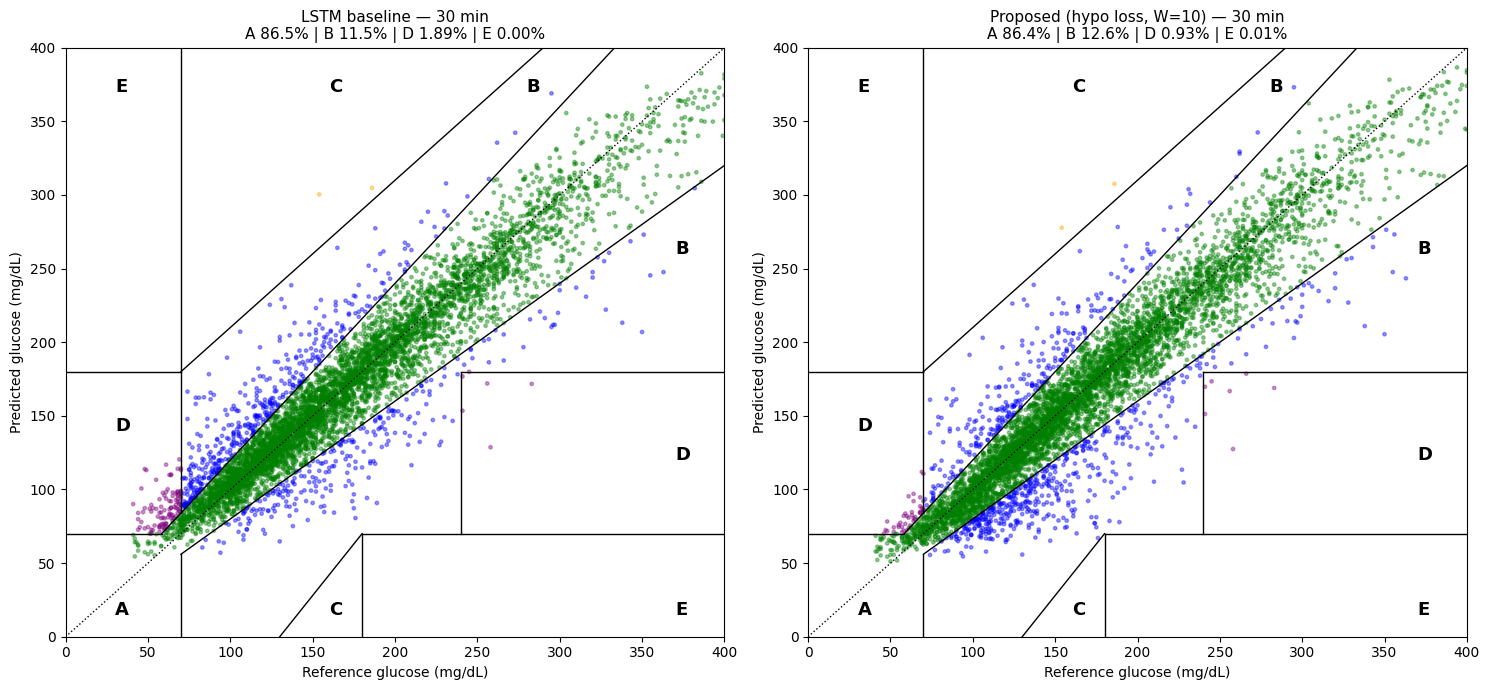

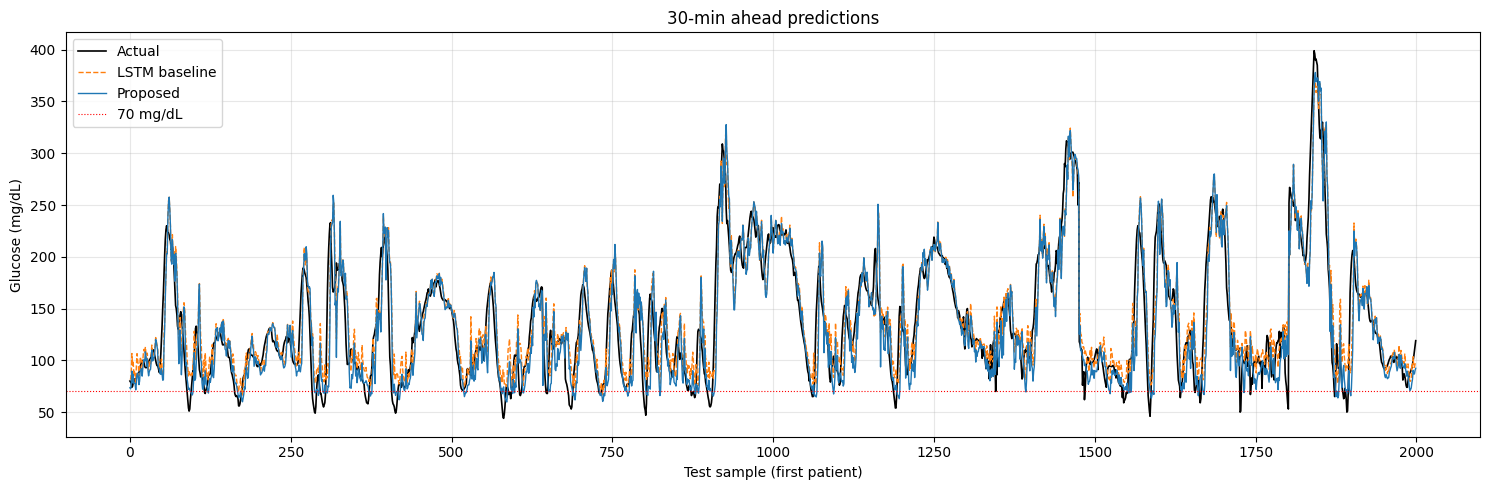

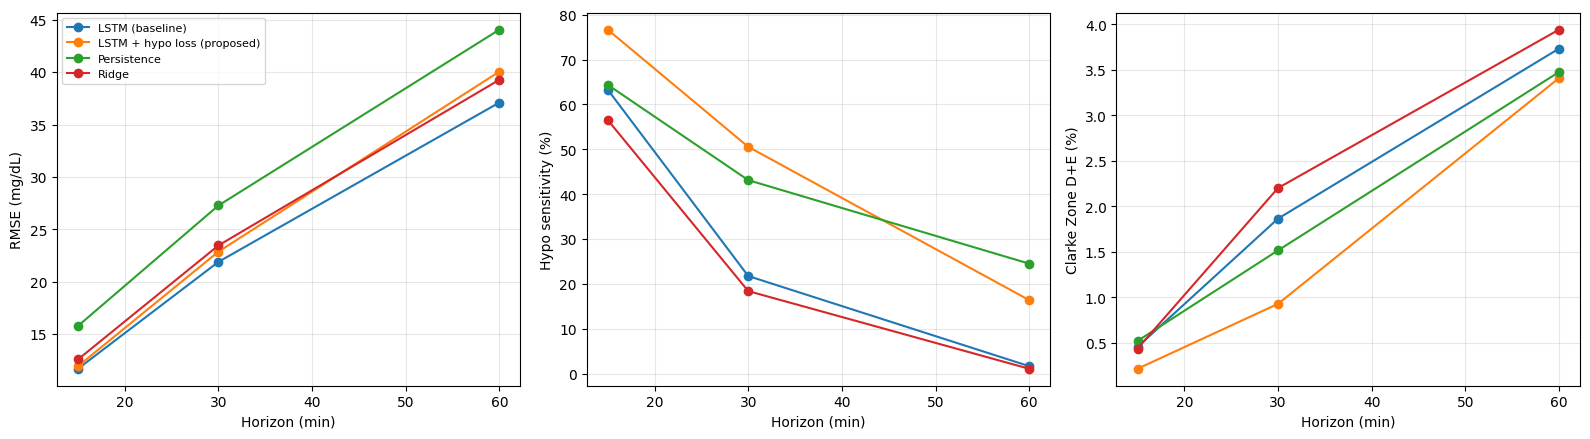

All tables and figures saved in D:\Dataset\DiaData2026\results


In [16]:
# ---------------------------------------------------------------
# Figures
# ---------------------------------------------------------------
def draw_clarke(ax, ref, pred, title, n_points=6000):
    z = clarke_zones(ref, pred)
    cmap = {'A': 'green', 'B': 'blue', 'C': 'orange', 'D': 'purple', 'E': 'red'}
    idx = np.random.default_rng(0).choice(len(ref), min(n_points, len(ref)), replace=False)
    ax.scatter(ref[idx], pred[idx], c=[cmap[k] for k in z[idx]], s=6, alpha=0.4)
    k = dict(color='black', linewidth=1)
    for xs, ys in [([0, 175/3], [70, 70]), ([175/3, 400/1.2], [70, 400]), ([70, 70], [84, 400]),
                   ([0, 70], [180, 180]), ([70, 290], [180, 400]), ([70, 70], [0, 56]),
                   ([70, 400], [56, 320]), ([180, 180], [0, 70]), ([180, 400], [70, 70]),
                   ([240, 240], [70, 180]), ([240, 400], [180, 180]), ([130, 180], [0, 70])]:
        ax.plot(xs, ys, **k)
    ax.plot([0, 400], [0, 400], ':', color='black', linewidth=1)
    for t, x, y in [('A', 30, 15), ('B', 370, 260), ('B', 280, 370), ('C', 160, 370), ('C', 160, 15),
                    ('D', 30, 140), ('D', 370, 120), ('E', 30, 370), ('E', 370, 15)]:
        ax.text(x, y, t, fontsize=13, fontweight='bold')
    pct = {q: np.mean(z == q) * 100 for q in 'ABCDE'}
    ax.set_title(f"{title}\nA {pct['A']:.1f}% | B {pct['B']:.1f}% | D {pct['D']:.2f}% | E {pct['E']:.2f}%",
                 fontsize=11)
    ax.set_xlim(0, 400); ax.set_ylim(0, 400)
    ax.set_xlabel('Reference glucose (mg/dL)'); ax.set_ylabel('Predicted glucose (mg/dL)')

h = MAIN_HORIZON
y_true = np.load(os.path.join(RESULTS_DIR, f"y_test_mgdl_h{h}.npy"))
s0 = SEEDS[0]
pred_base = np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_LSTM_level_W1_s{s0}.npz"))['y_pred']
pred_prop = np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_LSTM_level_W{W_BEST}_s{s0}.npz"))['y_pred']

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
draw_clarke(axes[0], y_true, pred_base, f'LSTM baseline — {h} min')
draw_clarke(axes[1], y_true, pred_prop, f'Proposed (hypo loss, W={W_BEST}) — {h} min')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'fig_clarke_baseline_vs_proposed.png'), dpi=200)
plt.show()

N = 2000
plt.figure(figsize=(15, 5))
plt.plot(y_true[:N], color='black', lw=1.2, label='Actual')
plt.plot(pred_base[:N], color='tab:orange', lw=1, ls='--', label='LSTM baseline')
plt.plot(pred_prop[:N], color='tab:blue', lw=1, label='Proposed')
plt.axhline(70, color='red', lw=0.8, ls=':', label='70 mg/dL')
plt.xlabel('Test sample (first patient)'); plt.ylabel('Glucose (mg/dL)')
plt.title(f'{h}-min ahead predictions'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'fig_predictions.png'), dpi=200); plt.show()

g = res[res['Method'].isin([BASE, PROPOSED, 'Persistence', 'Ridge'])] \
        .groupby(['horizon', 'Method'])[['RMSE', 'HypoSens', 'Zone_DE']].mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, yl in zip(axes, ['RMSE', 'HypoSens', 'Zone_DE'],
                       ['RMSE (mg/dL)', 'Hypo sensitivity (%)', 'Clarke Zone D+E (%)']):
    for mth, gg in g.groupby('Method'):
        ax.plot(gg['horizon'], gg[col], marker='o', label=mth)
    ax.set_xlabel('Horizon (min)'); ax.set_ylabel(yl); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'fig_horizons.png'), dpi=200); plt.show()
print(f"All tables and figures saved in {os.path.abspath(RESULTS_DIR)}")

## Step F — W sweep: the accuracy / hypo trade-off (30 min)
W is a dial, not a single "best" value. Every W is trained with all seeds so the curve is reliable.
The pre-defined validation rule from Step B is re-applied to the extended grid and reported honestly.

In [17]:
SWEEP_W = [1, 3, 5, 10, 15, 20]

del ds; GPU_DATA.clear(); gc.collect()
if device.type == 'cuda': torch.cuda.empty_cache()
ds = build_dataset(HORIZONS[MAIN_HORIZON])

for seed in SEEDS:
    for W in SWEEP_W:
        run_neural(ds, 'LSTM', 'level', W, seed)

res_all = load_results()
sw = res_all[(res_all['horizon'] == MAIN_HORIZON) & (res_all['model'] == 'LSTM') &
             (res_all['target'] == 'level') & (res_all['W'].isin(SWEEP_W))]
if 'held_out' in sw.columns:
    sw = sw[sw['held_out'].isna()]
sweep = sw.groupby('W')[['RMSE', 'MARD', 'Zone_DE', 'HypoSens', 'HypoPrec', 'HypoBias',
                         'val_RMSE', 'val_Zone_DE']].mean()
print("W sweep (mean over seeds, test set):")
print(sweep.drop(columns=['val_RMSE', 'val_Zone_DE']).round(2).to_string())

# Same rule as Step B, on the level target and the extended grid (validation only)
v0 = sweep.loc[1, 'val_RMSE']
ok = sweep[sweep['val_RMSE'] <= RMSE_TOLERANCE * v0]
W_RULE = int(ok['val_Zone_DE'].idxmin())
print(f"\nValidation rule on the extended grid would choose W = {W_RULE} "
      f"(main results use W = {W_BEST}, chosen in Step B).")
sweep.to_csv(os.path.join(RESULTS_DIR, 'sweep_W_30min.csv'))

[30-min] patients 200 | train 1,919,015 | val 479,856 | test 1,723,688 windows
  [cached] h30_LSTM_level_W1_s0
  [cached] h30_LSTM_level_W3_s0
  [cached] h30_LSTM_level_W5_s0
  [cached] h30_LSTM_level_W10_s0
  [cached] h30_LSTM_level_W15_s0
  [cached] h30_LSTM_level_W20_s0
  [cached] h30_LSTM_level_W1_s1
  [cached] h30_LSTM_level_W3_s1
  [cached] h30_LSTM_level_W5_s1
  [cached] h30_LSTM_level_W10_s1
  [cached] h30_LSTM_level_W15_s1
  [cached] h30_LSTM_level_W20_s1
  [cached] h30_LSTM_level_W1_s2
  [cached] h30_LSTM_level_W3_s2
  [cached] h30_LSTM_level_W5_s2
  [cached] h30_LSTM_level_W10_s2
  [cached] h30_LSTM_level_W15_s2
  [cached] h30_LSTM_level_W20_s2
W sweep (mean over seeds, test set):
     RMSE   MARD  Zone_DE  HypoSens  HypoPrec  HypoBias
W                                                      
1   21.89  10.33     1.86     21.77     70.90     21.32
3   22.12  10.01     1.30     36.46     60.61     15.49
5   22.36  10.04     1.07     45.59     55.02     13.25
10  22.87  10.19   

## Step G — event-based hypoglycaemia detection
Clinicians judge *episodes*, not single readings.

- **Hypo event:** at least 3 consecutive real readings (≥15 min) below 70 mg/dL; events less than
  30 min apart are merged. Onset = first reading below 70.
- **Alarm (predictive):** a forecast below 70 mg/dL issued while the *current* glucose is still ≥ 70 mg/dL.
  An "alarm" when glucose is already low predicts nothing, so it is not counted.
  Its *issue time* is the target time minus the horizon.
- **Warning time:** onset − earliest alarm issued between (horizon + 15 min) before onset and the onset.
- **Detected event:** warning time **≥ 10 min** (main metric) or ≥ 15 min.
- Persistence can never raise a predictive alarm (it only repeats the current value), so it scores 0 here
  by construction; it is kept in the table as that reference point.
- **False alarm:** an alarm episode (alarms ≤15 min apart) with no real reading below 70 from its
  start to (its end + horizon + 15 min). Reported per patient-day of test data.


=== Event-based hypo detection — 15 min (mean over seeds) ===
    Detected_% = predictive alarm >= 10 min before onset
                             Events  Detected_%  Detected_15min_%  Median_warning_min  FalseAlarms_per_day  Alarm_precision_%
Method                                                                                                                       
Persistence                  4527.0        0.00              0.00                 NaN                 0.00               0.00
Ridge                        4527.0       26.44              9.79                10.0                 0.28              64.98
LSTM (baseline)              4527.0       32.07             11.70                10.0                 0.19              77.16
LSTM + hypo loss (proposed)  4527.0       59.87             27.09                10.0                 0.42              67.64

=== Event-based hypo detection — 30 min (mean over seeds) ===
    Detected_% = predictive alarm >= 10 min before onset
    

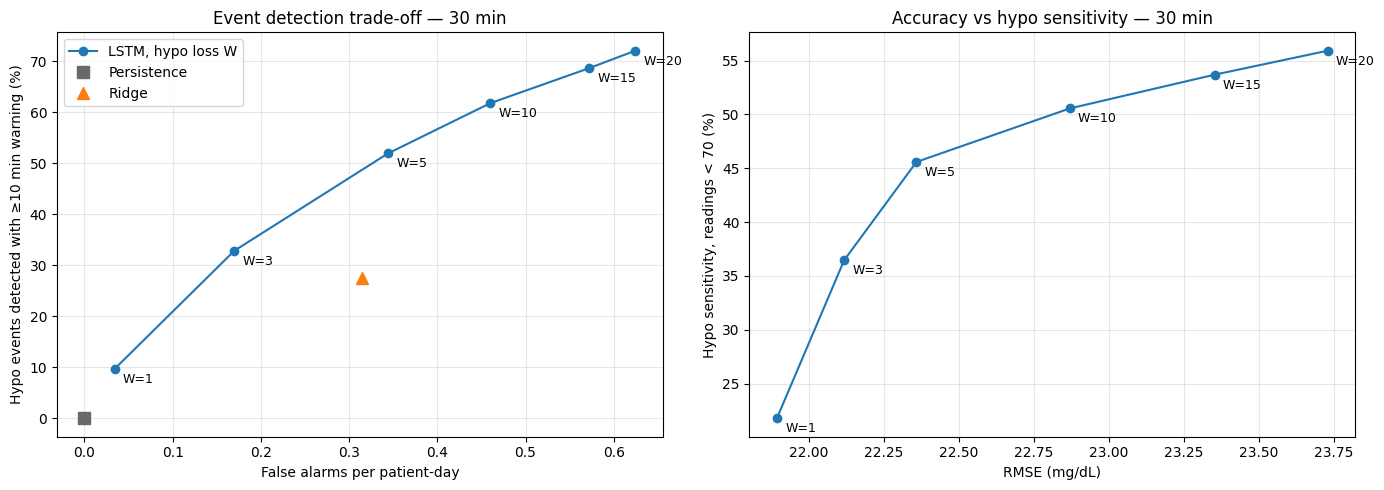

    Events  Detected_%  Detected_15min_%  Median_warning_min  FalseAlarms_per_day  Alarm_precision_%
W                                                                                                   
1   4481.0        9.71              6.15               15.00                 0.03              78.56
3   4481.0       32.85             21.40               15.00                 0.17              71.17
5   4481.0       51.92             36.20               15.00                 0.34              65.52
10  4481.0       61.79             44.01               15.00                 0.46              62.89
15  4481.0       68.65             50.25               16.67                 0.57              59.63
20  4481.0       72.06             53.57               16.67                 0.62              58.69


In [18]:
WARN_MAIN, WARN_LONG = 10, 15      # minutes of warning required for a detection

def event_metrics(y_true, t, pat, y_pred, h, current, thr=70, min_len=3, merge_gap=30):
    n_ev = n_fa = n_alarm_ep = 0
    leads, days = [], 0.0          # one entry per event: warning time, or -1 if no alarm
    bounds = np.r_[0, np.flatnonzero(np.diff(pat)) + 1, len(pat)]
    for a, b in zip(bounds[:-1], bounds[1:]):
        y, tt, yp, cur = y_true[a:b], t[a:b], y_pred[a:b], current[a:b]
        days += (b - a) * 5 / 1440
        low = y < thr
        # runs of consecutive (5-min apart) low readings
        brk = np.r_[True, ~(low[1:] & low[:-1] & (np.diff(tt) == 5))]
        run_id = np.cumsum(brk)
        onsets, ends = [], []
        for r in np.unique(run_id[low]):
            idx = np.flatnonzero((run_id == r) & low)
            if len(idx) >= min_len:
                if onsets and tt[idx[0]] - ends[-1] < merge_gap:
                    ends[-1] = tt[idx[-1]]
                else:
                    onsets.append(tt[idx[0]]); ends.append(tt[idx[-1]])
        s_al = tt[(yp < thr) & (cur >= thr)] - h        # predictive alarm issue times (sorted)
        for o in onsets:
            i = np.searchsorted(s_al, o - h - 15, 'left')
            j = np.searchsorted(s_al, o, 'right')
            leads.append(o - s_al[i] if j > i else -1)
        n_ev += len(onsets)
        if len(s_al):
            ep = np.r_[0, np.flatnonzero(np.diff(s_al) > 15) + 1, len(s_al)]
            lt = tt[low]
            for e0, e1 in zip(ep[:-1], ep[1:]):
                s0, s1 = s_al[e0], s_al[e1 - 1]
                n_alarm_ep += 1
                if np.searchsorted(lt, s0, 'left') >= np.searchsorted(lt, s1 + h + 15, 'right'):
                    n_fa += 1
    L = np.array(leads, float)
    det = L >= WARN_MAIN
    return {'Events': n_ev,
            'Detected_%': 100 * np.mean(det) if n_ev else np.nan,          # warning >= 10 min
            'Detected_15min_%': 100 * np.mean(L >= WARN_LONG) if n_ev else np.nan,
            'Median_warning_min': float(np.median(L[det])) if det.any() else np.nan,
            'FalseAlarms_per_day': n_fa / max(days, 1e-9),
            'Alarm_precision_%': 100 * (n_alarm_ep - n_fa) / max(n_alarm_ep, 1)}

res_all = load_results()
if 'held_out' in res_all.columns:
    res_all = res_all[res_all['held_out'].isna()]
rows = []
for h in sorted(res_all['horizon'].unique()):
    y_true = np.load(os.path.join(RESULTS_DIR, f"y_test_mgdl_h{h}.npy"))
    t_test = np.load(os.path.join(RESULTS_DIR, f"t_test_h{h}.npy"))
    p_test = np.load(os.path.join(RESULTS_DIR, f"p_test_h{h}.npy"))
    # current glucose at issue time = last input value = the persistence forecast
    current = np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_Persistence.npz"))['y_pred']
    for _, r in res_all[res_all['horizon'] == h].iterrows():
        yp = np.load(os.path.join(RESULTS_DIR, 'preds', f"{r['run_id']}.npz"))['y_pred']
        assert len(yp) == len(y_true), r['run_id']
        rows.append({'horizon': h, 'model': r['model'], 'target': r['target'], 'W': int(r['W']),
                     'seed': r['seed'], **event_metrics(y_true, t_test, p_test, yp, h, current)})
ev = pd.DataFrame(rows)
ev.to_csv(os.path.join(RESULTS_DIR, 'event_metrics_all_runs.csv'), index=False)

ev['Method'] = ev.apply(label, axis=1)
ecols = ['Events', 'Detected_%', 'Detected_15min_%', 'Median_warning_min',
         'FalseAlarms_per_day', 'Alarm_precision_%']
main = ['Persistence', 'Ridge', 'CNN', 'CNN-BiLSTM-Attn', 'LSTM (baseline)',
        'LSTM + hypo loss (proposed)']
for h in sorted(ev['horizon'].unique()):
    t = ev[(ev['horizon'] == h) & ev['Method'].isin(main)].groupby('Method')[ecols].mean()
    t = t.reindex([m for m in main if m in t.index]).round(2)
    print(f"\n=== Event-based hypo detection — {h} min (mean over seeds) ===")
    print(f"    Detected_% = predictive alarm >= {WARN_MAIN} min before onset")
    print(t.to_string())
    t.to_csv(os.path.join(RESULTS_DIR, f'events_{h}min.csv'))

# Trade-off figure (30 min): W sweep vs persistence / ridge
evs = ev[(ev['horizon'] == MAIN_HORIZON) & (ev['model'] == 'LSTM') & (ev['target'] == 'level') &
         (ev['W'].isin(SWEEP_W))].groupby('W')[ecols].mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(evs['FalseAlarms_per_day'], evs['Detected_%'], 'o-', color='tab:blue', label='LSTM, hypo loss W')
for W, r in evs.iterrows():
    ax.annotate(f"W={W}", (r['FalseAlarms_per_day'], r['Detected_%']), textcoords='offset points',
                xytext=(6, -10), fontsize=9)
for name, mk, col in [('Persistence', 's', 'dimgray'), ('Ridge', '^', 'tab:orange')]:
    e = ev[(ev['horizon'] == MAIN_HORIZON) & (ev['model'] == name)]
    if len(e):
        ax.plot(e['FalseAlarms_per_day'].mean(), e['Detected_%'].mean(), mk, ms=9, color=col, label=name)
ax.set_xlabel('False alarms per patient-day')
ax.set_ylabel(f'Hypo events detected with ≥{WARN_MAIN} min warning (%)')
ax.set_title(f'Event detection trade-off — {MAIN_HORIZON} min'); ax.grid(alpha=0.3); ax.legend()

ax = axes[1]
ax.plot(sweep['RMSE'], sweep['HypoSens'], 'o-', color='tab:blue')
for W, r in sweep.iterrows():
    ax.annotate(f"W={W}", (r['RMSE'], r['HypoSens']), textcoords='offset points', xytext=(6, -10), fontsize=9)
ax.set_xlabel('RMSE (mg/dL)'); ax.set_ylabel('Hypo sensitivity, readings < 70 (%)')
ax.set_title(f'Accuracy vs hypo sensitivity — {MAIN_HORIZON} min'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'fig_tradeoff_W.png'), dpi=200); plt.show()
print(evs.round(2).to_string())

### Step G2 — 95% confidence intervals for the event metrics
Bootstrap over **patients** (2,000 resamples). The same resampled patients are used for every model,
so differences between models are paired. Counts are averaged over seeds first.
No training — this only reads the saved predictions.

In [19]:
def event_counts(y_true, t, pat, y_pred, h, current, thr=70, min_len=3, merge_gap=30):
    # Same rules as event_metrics, returned per patient:
    # columns = events, detected (>=WARN_MAIN), detected (>=WARN_LONG), false-alarm episodes,
    #           alarm episodes, patient-days
    bounds = np.r_[0, np.flatnonzero(np.diff(pat)) + 1, len(pat)]
    out = np.zeros((len(bounds) - 1, 6))
    for k, (a, b) in enumerate(zip(bounds[:-1], bounds[1:])):
        y, tt, yp, cur = y_true[a:b], t[a:b], y_pred[a:b], current[a:b]
        low = y < thr
        brk = np.r_[True, ~(low[1:] & low[:-1] & (np.diff(tt) == 5))]
        run_id = np.cumsum(brk)
        onsets, ends = [], []
        for r in np.unique(run_id[low]):
            idx = np.flatnonzero((run_id == r) & low)
            if len(idx) >= min_len:
                if onsets and tt[idx[0]] - ends[-1] < merge_gap:
                    ends[-1] = tt[idx[-1]]
                else:
                    onsets.append(tt[idx[0]]); ends.append(tt[idx[-1]])
        s_al = tt[(yp < thr) & (cur >= thr)] - h
        d10 = d15 = 0
        for o in onsets:
            i = np.searchsorted(s_al, o - h - 15, 'left')
            j = np.searchsorted(s_al, o, 'right')
            if j > i:
                lead = o - s_al[i]
                d10 += lead >= WARN_MAIN; d15 += lead >= WARN_LONG
        fa = n_ep = 0
        if len(s_al):
            ep = np.r_[0, np.flatnonzero(np.diff(s_al) > 15) + 1, len(s_al)]
            lt = tt[low]
            for e0, e1 in zip(ep[:-1], ep[1:]):
                n_ep += 1
                if np.searchsorted(lt, s_al[e0], 'left') >= np.searchsorted(lt, s_al[e1 - 1] + h + 15, 'right'):
                    fa += 1
        out[k] = [len(onsets), d10, d15, fa, n_ep, (b - a) * 5 / 1440]
    return out

def rates(c):
    ev, d10, d15, fa, n_ep, days = c.sum(axis=0)
    return np.array([100 * d10 / max(ev, 1), 100 * d15 / max(ev, 1), fa / max(days, 1e-9)])

N_BOOT = 2000
res_ci = load_results()
if 'held_out' in res_ci.columns:
    res_ci = res_ci[res_ci['held_out'].isna()]
res_ci['Method'] = res_ci.apply(label, axis=1)
CI_METHODS = ['Ridge', 'CNN', 'CNN-BiLSTM-Attn', 'LSTM (baseline)', 'LSTM + hypo loss (proposed)']
ci_rows, diff_rows = [], []

for h in sorted(res_ci['horizon'].unique()):
    y_true = np.load(os.path.join(RESULTS_DIR, f"y_test_mgdl_h{h}.npy"))
    t_test = np.load(os.path.join(RESULTS_DIR, f"t_test_h{h}.npy"))
    p_test = np.load(os.path.join(RESULTS_DIR, f"p_test_h{h}.npy"))
    current = np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_Persistence.npz"))['y_pred']

    groups = {m: res_ci[(res_ci['horizon'] == h) & (res_ci['Method'] == m)]['run_id'].tolist()
              for m in CI_METHODS}
    if h == MAIN_HORIZON:   # W=5 operating point: false-alarm rate comparable to ridge
        groups['LSTM + hypo loss (W=5)'] = [f"h{h}_LSTM_level_W5_s{s}" for s in SEEDS]
    counts = {}
    for m, ids in groups.items():
        ids = [i for i in ids if os.path.exists(os.path.join(RESULTS_DIR, 'preds', f"{i}.npz"))]
        if not ids:
            continue
        cs = [event_counts(y_true, t_test, p_test,
                           np.load(os.path.join(RESULTS_DIR, 'preds', f"{i}.npz"))['y_pred'], h, current)
              for i in ids]
        counts[m] = np.mean(cs, axis=0)          # average over seeds, per patient

    # consistency check against Step G (seed-averaged counts vs seed-averaged rates can differ slightly)
    n_pat = len(next(iter(counts.values())))
    rs = np.random.default_rng(0)
    boot_idx = [rs.integers(0, n_pat, n_pat) for _ in range(N_BOOT)]
    boots = {m: np.array([rates(c[i]) for i in boot_idx]) for m, c in counts.items()}

    for m, c in counts.items():
        est, lo, hi = rates(c), np.percentile(boots[m], 2.5, axis=0), np.percentile(boots[m], 97.5, axis=0)
        ci_rows.append({'horizon': h, 'Method': m, 'Events': int(round(c[:, 0].sum())),
                        'Detected ≥10 min (%)': f"{est[0]:.1f} [{lo[0]:.1f}, {hi[0]:.1f}]",
                        'Detected ≥15 min (%)': f"{est[1]:.1f} [{lo[1]:.1f}, {hi[1]:.1f}]",
                        'False alarms / day':   f"{est[2]:.2f} [{lo[2]:.2f}, {hi[2]:.2f}]"})

    pairs = [('LSTM + hypo loss (proposed)', 'LSTM (baseline)')]
    if h == MAIN_HORIZON:
        pairs += [('LSTM + hypo loss (W=5)', 'Ridge'), ('LSTM + hypo loss (proposed)', 'Ridge')]
    for a, b in pairs:
        if a in counts and b in counts:
            d = boots[a] - boots[b]
            est = rates(counts[a]) - rates(counts[b])
            lo, hi = np.percentile(d, 2.5, axis=0), np.percentile(d, 97.5, axis=0)
            diff_rows.append({'horizon': h, 'Comparison': f"{a}  minus  {b}",
                              'Δ Detected ≥10 min (points)': f"{est[0]:+.1f} [{lo[0]:+.1f}, {hi[0]:+.1f}]",
                              'Δ Detected ≥15 min (points)': f"{est[1]:+.1f} [{lo[1]:+.1f}, {hi[1]:+.1f}]",
                              'Δ False alarms / day':        f"{est[2]:+.2f} [{lo[2]:+.2f}, {hi[2]:+.2f}]"})

ci_df, diff_df = pd.DataFrame(ci_rows), pd.DataFrame(diff_rows)
for h in sorted(ci_df['horizon'].unique()):
    print(f"\n=== {h} min — event metrics with 95% bootstrap CI (over patients) ===")
    print(ci_df[ci_df['horizon'] == h].drop(columns='horizon').to_string(index=False))
    dd = diff_df[diff_df['horizon'] == h]
    if len(dd):
        print("\n  Paired differences (95% CI; an interval not containing 0 = clear difference):")
        print(dd.drop(columns='horizon').to_string(index=False))
ci_df.to_csv(os.path.join(RESULTS_DIR, 'events_with_CI.csv'), index=False)
diff_df.to_csv(os.path.join(RESULTS_DIR, 'events_differences_CI.csv'), index=False)
print(f"\nSaved events_with_CI.csv and events_differences_CI.csv in {RESULTS_DIR}")


=== 15 min — event metrics with 95% bootstrap CI (over patients) ===
                     Method  Events Detected ≥10 min (%) Detected ≥15 min (%) False alarms / day
                      Ridge    4527    26.4 [24.4, 28.4]      9.8 [8.7, 10.9]  0.28 [0.24, 0.33]
            LSTM (baseline)    4527    32.1 [29.7, 34.4]    11.7 [10.6, 12.9]  0.19 [0.17, 0.21]
LSTM + hypo loss (proposed)    4527    59.9 [57.8, 61.9]    27.1 [25.5, 28.7]  0.42 [0.37, 0.48]

  Paired differences (95% CI; an interval not containing 0 = clear difference):
                                         Comparison Δ Detected ≥10 min (points) Δ Detected ≥15 min (points) Δ False alarms / day
LSTM + hypo loss (proposed)  minus  LSTM (baseline)        +27.8 [+26.4, +29.2]        +15.4 [+14.4, +16.3] +0.23 [+0.20, +0.27]

=== 30 min — event metrics with 95% bootstrap CI (over patients) ===
                     Method  Events Detected ≥10 min (%) Detected ≥15 min (%) False alarms / day
                      Ridge    4481 

### Step G3 — is the weighted loss better than simply raising the alarm threshold?
A reviewer's obvious question: instead of retraining, keep the normal model and alarm when its forecast is
below a **higher threshold θ** (e.g. 80 or 90 mg/dL). That also trades false alarms for detection, and it does
not change RMSE at all. Here every model's alarm threshold θ is swept from 60 to 130 mg/dL
(episodes are still defined as true glucose < 70; an alarm still requires current glucose ≥ 70), and the
models are compared **at the same false-alarm rate**. No training — only saved predictions are used.

**How to read it:** if the weighted model detects clearly more episodes than the threshold-shifted baseline
at the same false-alarm rate (95% CI above 0), the loss adds real value. If not, threshold shifting is enough,
and the paper's message must change.

  [15 min] LSTM (baseline): 3 run(s)
  [15 min] Ridge: 1 run(s)
  [15 min] LSTM + hypo loss (W=10): 3 run(s)
  [30 min] LSTM (baseline): 3 run(s)
  [30 min] Ridge: 1 run(s)
  [30 min] LSTM + hypo loss (W=5): 3 run(s)
  [30 min] LSTM + hypo loss (W=10): 3 run(s)
  [60 min] LSTM (baseline): 3 run(s)
  [60 min] Ridge: 1 run(s)
  [60 min] LSTM + hypo loss (W=10): 3 run(s)

=== 15 min — episodes detected (%) at a FIXED false-alarm rate [95% CI] ===
 FA/day   LSTM (baseline)             Ridge LSTM + hypo loss (W=10)
   0.10 17.5 [15.0, 20.6]    6.6 [4.9, 8.5]       16.0 [13.1, 19.4]
   0.25 40.0 [35.8, 45.0] 22.6 [18.5, 27.7]       38.8 [34.2, 44.1]
   0.50 64.3 [59.4, 69.7] 51.3 [45.1, 57.7]       65.7 [61.0, 71.1]

=== 15 min — weighted model (θ=70) vs threshold-shifted models at the SAME false-alarm rate ===
  Weighted model (θ=70)                          vs  FA/day  θ needed (mg/dL)  Det. weighted (%)  Det. shifted (%) Δ detection [95% CI]  RMSE weighted  RMSE shifted
LSTM + hypo loss (

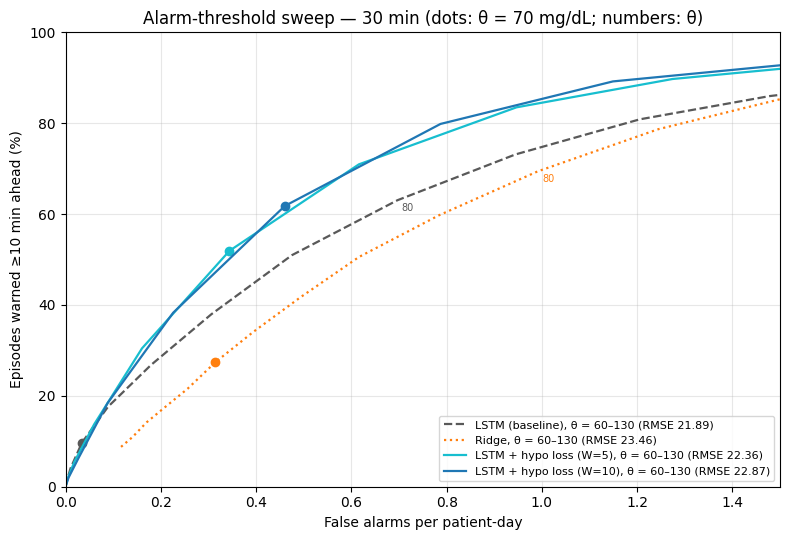

In [20]:
THRESHOLDS = np.arange(60, 132, 2)          # alarm thresholds (mg/dL)
FA_LEVELS  = [0.1, 0.25, 0.5]               # false alarms per patient-day for fixed-rate comparisons

def event_counts_thr(y_true, t, pat, y_pred, h, current, thresholds, thr=70, min_len=3, merge_gap=30):
    # Per threshold and patient: [events, detected >=WARN_MAIN, detected >=WARN_LONG, false alarms, alarm episodes, days]
    bounds = np.r_[0, np.flatnonzero(np.diff(pat)) + 1, len(pat)]
    out = np.zeros((len(thresholds), len(bounds) - 1, 6))
    for k, (a, b) in enumerate(zip(bounds[:-1], bounds[1:])):
        y, tt, yp, cur = y_true[a:b], t[a:b], y_pred[a:b], current[a:b]
        low = y < thr
        brk = np.r_[True, ~(low[1:] & low[:-1] & (np.diff(tt) == 5))]
        run_id = np.cumsum(brk)
        onsets, ends = [], []
        for r in np.unique(run_id[low]):
            idx = np.flatnonzero((run_id == r) & low)
            if len(idx) >= min_len:
                if onsets and tt[idx[0]] - ends[-1] < merge_gap:
                    ends[-1] = tt[idx[-1]]
                else:
                    onsets.append(tt[idx[0]]); ends.append(tt[idx[-1]])
        onsets = np.array(onsets, dtype=np.int64)
        lt, days = tt[low], (b - a) * 5 / 1440
        ok_cur = cur >= thr
        for q, th in enumerate(thresholds):
            s_al = tt[(yp < th) & ok_cur] - h
            d10 = d15 = fa = n_ep = 0
            if len(s_al):
                if len(onsets):
                    i = np.searchsorted(s_al, onsets - h - 15, 'left')
                    j = np.searchsorted(s_al, onsets, 'right')
                    hit = j > i
                    lead = np.where(hit, onsets - s_al[np.minimum(i, len(s_al) - 1)], -1)
                    d10, d15 = np.sum(lead >= WARN_MAIN), np.sum(lead >= WARN_LONG)
                ep = np.r_[0, np.flatnonzero(np.diff(s_al) > 15) + 1, len(s_al)]
                s0, s1 = s_al[ep[:-1]], s_al[ep[1:] - 1]
                lo = np.searchsorted(lt, s0, 'left'); hi = np.searchsorted(lt, s1 + h + 15, 'right')
                fa, n_ep = int(np.sum(lo >= hi)), len(s0)
            out[q, k] = [len(onsets), d10, d15, fa, n_ep, days]
    return out

def curve(c):
    # c: (n_thr, n_pat, 6) -> detection % and false alarms/day per threshold
    tot = c.sum(axis=1)
    return 100 * tot[:, 1] / np.maximum(tot[:, 0], 1), tot[:, 3] / np.maximum(tot[:, 5], 1e-9)

def det_at_fa(det, fa, f):
    o = np.argsort(fa)
    fa_s, det_s = fa[o], np.maximum.accumulate(det[o])
    return np.interp(f, fa_s, det_s) if fa_s[0] <= f <= fa_s[-1] else np.nan

res_t = load_results()
if 'held_out' in res_t.columns:
    res_t = res_t[res_t['held_out'].isna()]
models_by_h = {h: [('LSTM (baseline)', 'LSTM', 'level', 1), ('Ridge', 'Ridge', 'level', 1),
                   ('LSTM + hypo loss (W=10)', 'LSTM', 'level', W_BEST)] for h in HORIZONS}
models_by_h[MAIN_HORIZON].insert(2, ('LSTM + hypo loss (W=5)', 'LSTM', 'level', 5))

thr_rows, fix_rows, match_rows, curves_store = [], [], [], {}
rs = np.random.default_rng(1)
for h in sorted(HORIZONS):
    f_y = os.path.join(RESULTS_DIR, f"y_test_mgdl_h{h}.npy")
    if not os.path.exists(f_y):
        continue
    y_true = np.load(f_y)
    t_test = np.load(os.path.join(RESULTS_DIR, f"t_test_h{h}.npy"))
    p_test = np.load(os.path.join(RESULTS_DIR, f"p_test_h{h}.npy"))
    current = np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_Persistence.npz"))['y_pred']
    counts = {}
    for name, model, target, W in models_by_h[h]:
        r = res_t[(res_t['horizon'] == h) & (res_t['model'] == model) & (res_t['W'] == W) &
                  ((res_t['target'] == target) | (model == 'Ridge'))]
        ids = [i for i in r['run_id'] if os.path.exists(os.path.join(RESULTS_DIR, 'preds', f"{i}.npz"))]
        if not ids:
            continue
        print(f"  [{h} min] {name}: {len(ids)} run(s)")
        cs = [event_counts_thr(y_true, t_test, p_test,
                               np.load(os.path.join(RESULTS_DIR, 'preds', f"{i}.npz"))['y_pred'],
                               h, current, THRESHOLDS) for i in ids]
        counts[name] = np.mean(cs, axis=0)
        rmse = r['RMSE'].mean()
        det, fa = curve(counts[name])
        curves_store[(h, name)] = (det, fa, rmse)
        for th, d, f in zip(THRESHOLDS, det, fa):
            thr_rows.append({'horizon': h, 'Model': name, 'theta': th, 'Detected_%': d,
                             'FalseAlarms_per_day': f, 'RMSE': rmse})

    n_pat = counts['LSTM (baseline)'].shape[1]
    boot_idx = [rs.integers(0, n_pat, n_pat) for _ in range(N_BOOT)]
    boot_curves = {m: [curve(c[:, i, :]) for i in boot_idx] for m, c in counts.items()}

    # (1) detection at fixed false-alarm rates
    for f in FA_LEVELS:
        row = {'horizon': h, 'FA/day': f}
        for m in counts:
            det, fa, _ = curves_store[(h, m)]
            est = det_at_fa(det, fa, f)
            bs = np.array([det_at_fa(d, a, f) for d, a in boot_curves[m]])
            lo, hi = np.nanpercentile(bs, [2.5, 97.5]) if np.isfinite(bs).any() else (np.nan, np.nan)
            row[m] = f"{est:.1f} [{lo:.1f}, {hi:.1f}]" if np.isfinite(est) else "out of range"
        fix_rows.append(row)

    # (2) matched comparison: weighted model at theta = 70 vs threshold-shifted LSTM / ridge at the same FA
    i70 = int(np.flatnonzero(THRESHOLDS == 70)[0])
    for wname in [m for m in counts if 'hypo loss' in m]:
        for bname in ['LSTM (baseline)', 'Ridge']:
            dW, fW, _ = curves_store[(h, wname)]
            dB, fB, rB = curves_store[(h, bname)]
            target_fa = fW[i70]
            est = dW[i70] - det_at_fa(dB, fB, target_fa)
            o = np.argsort(fB)
            theta_needed = np.interp(target_fa, fB[o], THRESHOLDS[o]) if fB[o][0] <= target_fa <= fB[o][-1] else np.nan
            diffs = []
            for (dw, fw), (db, fb) in zip(boot_curves[wname], boot_curves[bname]):
                diffs.append(dw[i70] - det_at_fa(db, fb, fw[i70]))
            diffs = np.array(diffs)
            lo, hi = np.nanpercentile(diffs, [2.5, 97.5]) if np.isfinite(diffs).any() else (np.nan, np.nan)
            match_rows.append({'horizon': h, 'Weighted model (θ=70)': wname, 'vs': bname + ' (θ shifted)',
                               'FA/day': round(float(target_fa), 3),
                               'θ needed (mg/dL)': round(float(theta_needed), 1) if np.isfinite(theta_needed) else 'n/a',
                               'Det. weighted (%)': round(float(dW[i70]), 1),
                               'Det. shifted (%)': round(float(dW[i70] - est), 1) if np.isfinite(est) else 'n/a',
                               'Δ detection [95% CI]': f"{est:+.1f} [{lo:+.1f}, {hi:+.1f}]" if np.isfinite(est) else 'n/a',
                               'RMSE weighted': round(curves_store[(h, wname)][2], 2),
                               'RMSE shifted': round(rB, 2)})

thr_df, fix_df, match_df = pd.DataFrame(thr_rows), pd.DataFrame(fix_rows), pd.DataFrame(match_rows)
thr_df.to_csv(os.path.join(RESULTS_DIR, 'threshold_sweep_curves.csv'), index=False)
fix_df.to_csv(os.path.join(RESULTS_DIR, 'threshold_detection_at_fixed_FA.csv'), index=False)
match_df.to_csv(os.path.join(RESULTS_DIR, 'threshold_matched_comparison.csv'), index=False)

pd.set_option('display.width', 250)
for h in sorted(match_df['horizon'].unique()):
    print(f"\n=== {h} min — episodes detected (%) at a FIXED false-alarm rate [95% CI] ===")
    print(fix_df[fix_df['horizon'] == h].drop(columns='horizon').dropna(axis=1, how='all').to_string(index=False))
    print(f"\n=== {h} min — weighted model (θ=70) vs threshold-shifted models at the SAME false-alarm rate ===")
    print(match_df[match_df['horizon'] == h].drop(columns='horizon').to_string(index=False))

# Figure: 30-min trade-off curves
h = MAIN_HORIZON
style = {'LSTM (baseline)': dict(color='0.35', ls='--'), 'Ridge': dict(color='tab:orange', ls=':'),
         'LSTM + hypo loss (W=5)': dict(color='tab:cyan', ls='-'),
         'LSTM + hypo loss (W=10)': dict(color='tab:blue', ls='-')}
fig, ax = plt.subplots(figsize=(8, 5.5))
for name, st in style.items():
    if (h, name) not in curves_store:
        continue
    det, fa, rmse = curves_store[(h, name)]
    ax.plot(fa, det, lw=1.6, label=f"{name}, θ = 60–130 (RMSE {rmse:.2f})", **st)
    i70 = int(np.flatnonzero(THRESHOLDS == 70)[0])
    ax.plot(fa[i70], det[i70], 'o', color=st['color'], ms=6)
    for th in (80, 90, 100):
        q = int(np.flatnonzero(THRESHOLDS == th)[0])
        if fa[q] <= 1.5:
            ax.annotate(f"{th}", (fa[q], det[q]), fontsize=7, color=st['color'],
                        textcoords='offset points', xytext=(3, -8))
ax.set_xlim(0, 1.5); ax.set_ylim(0, 100)
ax.set_xlabel('False alarms per patient-day'); ax.set_ylabel(f'Episodes warned ≥{WARN_MAIN} min ahead (%)')
ax.set_title(f'Alarm-threshold sweep — {h} min (dots: θ = 70 mg/dL; numbers: θ)')
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'fig_threshold_sweep.png'), dpi=200); plt.show()

## Step H — leave-one-study-out (30 min)
For each source study with enough sampled patients: train the baseline and the proposed LSTM
**without** that study, then test on that study's patients. Compare with the models trained on all
studies (Step A/C, seed 0). A small drop means the result generalises to new cohorts/devices.

*Note:* each patient's glucose scaling (min/max) still comes from that patient's own training
period, so this tests generalisation of the learned dynamics, not calibration-free deployment.

In [21]:
MIN_STUDY_PATIENTS = 10
LOSO_SEED = SEEDS[0]

pat_study = np.array([patient_study.get(p, 'unknown') for p in ds['pids']])
counts = pd.Series(pat_study).value_counts()
LOSO_STUDIES = [s for s, c in counts.items() if c >= MIN_STUDY_PATIENTS]
print("Held-out studies:", LOSO_STUDIES)

def run_loso(ds, study, W, seed=LOSO_SEED):
    h = ds['horizon_min']
    run_id = f"h{h}_LOSO-{study}_LSTM_level_W{W}_s{seed}"
    held = pat_study == study
    te = np.flatnonzero(held[ds['p_test']])
    if (r := cached(run_id, len(te))) is not None:
        print(f"  [cached] {run_id}"); return r
    print(f"\n>>> {run_id}")
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    tr = ds['tr_idx'][~held[ds['p_train'][ds['tr_idx']]]]
    va = ds['va_idx'][~held[ds['p_train'][ds['va_idx']]]]
    X, y = gpu_tensors(ds)
    Wt = None if W == 1 else torch.from_numpy(hypo_weights(ds['y_train_mgdl'], W)).to(X.device)
    model = MODELS['LSTM'](X.shape[2]).to(device)
    t0 = time.time()
    hist = train_model(model, X, y, Wt, tr, va, seed)
    y_pred = to_mgdl(ds, predict(model, ds['X_test'], te), ds['p_test'][te])
    m, pp = evaluate(ds['y_test_mgdl'][te], y_pred, ds['p_test'][te])
    del model, Wt
    if device.type == 'cuda': torch.cuda.empty_cache()
    row = {'run_id': run_id, 'horizon': h, 'model': 'LSTM', 'target': 'level', 'W': W, 'seed': seed,
           'held_out': study, 'epochs': len(hist), 'train_min': round((time.time() - t0) / 60, 1), **m}
    np.savez_compressed(os.path.join(RESULTS_DIR, 'preds', f"{run_id}.npz"),
                        y_pred=y_pred.astype(np.float32), te=te)
    save_row(row)
    print(f"  -> {run_id}: RMSE {m['RMSE']:.2f} | hypo sens {m['HypoSens']:.1f}%")
    return row

for study in LOSO_STUDIES:
    for W in [1, W_BEST]:
        run_loso(ds, study, W)

# Compare with the all-studies models (same seed), restricted to the held-out study's patients
rows = []
for study in LOSO_STUDIES:
    te = np.flatnonzero((pat_study == study)[ds['p_test']])
    yt, pt = ds['y_test_mgdl'][te], ds['p_test'][te]
    for W, name in [(1, 'Baseline'), (W_BEST, 'Proposed')]:
        all_pred = np.load(os.path.join(RESULTS_DIR, 'preds',
                                        f"h{MAIN_HORIZON}_LSTM_level_W{W}_s{LOSO_SEED}.npz"))['y_pred'][te]
        loso_pred = np.load(os.path.join(RESULTS_DIR, 'preds',
                                         f"h{MAIN_HORIZON}_LOSO-{study}_LSTM_level_W{W}_s{LOSO_SEED}.npz"))['y_pred']
        m_all, _ = evaluate(yt, all_pred, pt)
        m_lo, _  = evaluate(yt, loso_pred, pt)
        rows.append({'Study': study, 'Patients': int(counts[study]), 'Model': name,
                     'RMSE (all studies)': m_all['RMSE'], 'RMSE (study held out)': m_lo['RMSE'],
                     'HypoSens (all)': m_all['HypoSens'], 'HypoSens (held out)': m_lo['HypoSens'],
                     'Zone D+E (all)': m_all['Zone_DE'], 'Zone D+E (held out)': m_lo['Zone_DE']})
loso = pd.DataFrame(rows)
loso['ΔRMSE'] = loso['RMSE (study held out)'] - loso['RMSE (all studies)']
print(loso.round(2).to_string(index=False))
print("\nMean over studies:")
print(loso.groupby('Model')[['RMSE (all studies)', 'RMSE (study held out)', 'ΔRMSE',
                             'HypoSens (all)', 'HypoSens (held out)']].mean().round(2).to_string())
loso.to_csv(os.path.join(RESULTS_DIR, 'loso_30min.csv'), index=False)

Held-out studies: ['RT-CGM', 'RBG', 'CITY', 'DLCP3', 'SHD', 'WISDM', 'PEDAP', 'SENCE']
  [cached] h30_LOSO-RT-CGM_LSTM_level_W1_s0
  [cached] h30_LOSO-RT-CGM_LSTM_level_W10_s0
  [cached] h30_LOSO-RBG_LSTM_level_W1_s0
  [cached] h30_LOSO-RBG_LSTM_level_W10_s0
  [cached] h30_LOSO-CITY_LSTM_level_W1_s0
  [cached] h30_LOSO-CITY_LSTM_level_W10_s0
  [cached] h30_LOSO-DLCP3_LSTM_level_W1_s0
  [cached] h30_LOSO-DLCP3_LSTM_level_W10_s0
  [cached] h30_LOSO-SHD_LSTM_level_W1_s0
  [cached] h30_LOSO-SHD_LSTM_level_W10_s0
  [cached] h30_LOSO-WISDM_LSTM_level_W1_s0
  [cached] h30_LOSO-WISDM_LSTM_level_W10_s0
  [cached] h30_LOSO-PEDAP_LSTM_level_W1_s0
  [cached] h30_LOSO-PEDAP_LSTM_level_W10_s0
  [cached] h30_LOSO-SENCE_LSTM_level_W1_s0
  [cached] h30_LOSO-SENCE_LSTM_level_W10_s0
 Study  Patients    Model  RMSE (all studies)  RMSE (study held out)  HypoSens (all)  HypoSens (held out)  Zone D+E (all)  Zone D+E (held out)  ΔRMSE
RT-CGM        51 Baseline               20.68                  20.92       

## Step I — reviewer-driven extra analyses (validation-tuned θ, rule baselines, weighted ridge, strict FA, level 2, seeds)
Run Steps A–H first (needs `ds` for the 30-min horizon, `df_raw`, the saved predictions and the Step G3 helpers).

| Cell | What it adds | Retrains? |
|---|---|---|
| I-1 | dense validation windows + `event_counts_thr2` (adds `fa_mode`) + bootstrap helpers | no |
| I-2 | reactive-rule and trend baselines, ridge and **weighted ridge** | no (closed form) |
| I-3 | re-train LSTM W = 1, 5, W_BEST (3 seeds) **saving validation predictions** | yes (9 runs, resumable) |
| I-4 | **threshold θ tuned on validation**, applied to test | no |
| I-5 | strict false-alarm definition, level-2 hypoglycaemia (< 54 mg/dL) | no |
| I-6 | W-sweep table with ± SD (no retraining) and LOSO with extra seeds | LOSO only |
| I-7 | updated Fig. 2 | no |

In [22]:
# ---------------------------------------------------------------
# Step I-1 — shared helpers
#  * dense VALIDATION windows (stride 1) so event metrics can be computed on validation data
#    (the stored validation set uses stride 3, which breaks the "3 consecutive readings" episode rule)
#  * event_counts_thr2 = event_counts_thr + fa_mode ('lenient' = paper default, 'strict')
#  * small bootstrap / table helpers
# ---------------------------------------------------------------
assert ds['horizon_min'] == MAIN_HORIZON, "rebuild ds for the 30-min horizon first"
H_MIN = ds['horizon_min']
STEPS = H_MIN // CGM_INTERVAL_MIN
# Alarm-threshold grid for Step I: wider than Step G3 (60-130) so that the trend baseline, whose forecasts
# often drop below 60, can also reach the low false-alarm rates. Other models are unaffected.
THR_I = np.arange(30, 132, 2)
VAL_DIR = os.path.join(RESULTS_DIR, 'preds_val'); os.makedirs(VAL_DIR, exist_ok=True)


def build_val_dense(ds):
    """Validation windows at stride 1, same time span and scaling as the stride-3 validation set."""
    steps = ds['horizon_min'] // CGM_INTERVAL_MIN
    k_of = {p: k for k, p in enumerate(ds['pids'])}
    Xv, yv, pv, tv = [], [], [], []
    n_val_stride3 = 0
    for pid, pdata in df_raw.groupby('PtID', sort=False):
        if pid not in k_of:
            continue
        pdata = pdata.sort_values('Time')
        valid = pdata[feature_columns].notna().all(axis=1)
        cutoff = pdata.loc[valid, 'Time'].iloc[int(valid.sum() * TRAIN_RATIO)]
        is_tr = (pdata['Time'] < cutoff).values
        fit = valid.values & is_tr
        sx, sy = MinMaxScaler(), MinMaxScaler()
        sx.fit(pdata.loc[fit, feature_columns].values)
        sy.fit(pdata.loc[fit, [target_column]].values)
        X_all = sx.transform(pdata[feature_columns].values)
        y_all = sy.transform(pdata[[target_column]].values).ravel()
        real = pdata['Is_real'].values
        tmin = pdata['Time'].values.astype('datetime64[m]').astype(np.int64)
        block = pdata['Seg'].astype(str).values + np.where(is_tr, '_tr', '_te')
        starts = np.r_[0, np.flatnonzero(block[1:] != block[:-1]) + 1, len(block)]

        # 1) stride-3 train windows (exactly as build_dataset) -> time where validation starts
        t_tr = []
        for a, b in zip(starts[:-1], starts[1:]):
            if not is_tr[a]:
                continue
            _, _, tp = make_windows(X_all[a:b], y_all[a:b], real[a:b], SEQ_LENGTH, steps,
                                    TRAIN_STRIDE, require_real_target=False)
            if tp is not None:
                t_tr.append(tmin[a:b][tp])
        if not t_tr:
            continue
        t_tr = np.concatenate(t_tr)
        n_cut = int(len(t_tr) * (1 - VAL_RATIO))
        t_val0 = t_tr[n_cut]
        n_val_stride3 += len(t_tr) - n_cut

        # 2) dense windows (stride 1, measured targets) whose target time >= t_val0
        for a, b in zip(starts[:-1], starts[1:]):
            if not is_tr[a]:
                continue
            s = max(0, int(np.searchsorted(tmin[a:b], t_val0, 'left')) - (SEQ_LENGTH + steps - 1))
            if b - a - s < SEQ_LENGTH + steps:
                continue
            Xd, yd, tpd = make_windows(X_all[a + s:b], y_all[a + s:b], real[a + s:b], SEQ_LENGTH,
                                       steps, 1, require_real_target=True)
            if Xd is None:
                continue
            td = tmin[a + s:b][tpd]
            keep = td >= t_val0
            if keep.any():
                Xv.append(Xd[keep]); yv.append(yd[keep]); tv.append(td[keep])
                pv.append(np.full(int(keep.sum()), k_of[pid], np.int32))
    assert n_val_stride3 == len(ds['va_idx']), (n_val_stride3, len(ds['va_idx']))   # same validation span
    dv = dict(X=np.concatenate(Xv), p=np.concatenate(pv), t=np.concatenate(tv))
    y_sc = np.concatenate(yv)
    dv['y'] = to_mgdl(ds, y_sc, dv['p'])
    dv['cur'] = to_mgdl(ds, dv['X'][:, -1, 0], dv['p'])        # current glucose at issue time
    print(f"dense validation windows: {len(dv['y']):,} "
          f"(stride-3 validation set: {len(ds['va_idx']):,})")
    return dv


def event_counts_thr2(y_true, t, pat, y_pred, h, current, thresholds, thr=70, min_len=3,
                      merge_gap=30, fa_mode='lenient'):
    """Same as event_counts_thr, plus
         thr      : hypoglycaemia level (episode definition AND alarm gate 'current >= thr')
         fa_mode  : 'lenient' (paper) -> alarm episode is a false alarm if no reading < thr occurs
                                         between its start and (last alarm + h + 15) min
                    'strict'          -> ... between its start and (first alarm + h + 15) min
       Output per threshold and patient: [events, det>=10min, det>=15min, FA, alarm episodes, days]."""
    assert fa_mode in ('lenient', 'strict')
    bounds = np.r_[0, np.flatnonzero(np.diff(pat)) + 1, len(pat)]
    out = np.zeros((len(thresholds), len(bounds) - 1, 6))
    for k, (a, b) in enumerate(zip(bounds[:-1], bounds[1:])):
        y, tt, yp, cur = y_true[a:b], t[a:b], y_pred[a:b], current[a:b]
        low = y < thr
        brk = np.r_[True, ~(low[1:] & low[:-1] & (np.diff(tt) == 5))]
        run_id = np.cumsum(brk)
        onsets, ends = [], []
        for r in np.unique(run_id[low]):
            idx = np.flatnonzero((run_id == r) & low)
            if len(idx) >= min_len:
                if onsets and tt[idx[0]] - ends[-1] < merge_gap:
                    ends[-1] = tt[idx[-1]]
                else:
                    onsets.append(tt[idx[0]]); ends.append(tt[idx[-1]])
        onsets = np.array(onsets, dtype=np.int64)
        lt, days = tt[low], (b - a) * 5 / 1440
        ok_cur = cur >= thr
        for q, th in enumerate(thresholds):
            s_al = tt[(yp < th) & ok_cur] - h
            d10 = d15 = fa = n_ep = 0
            if len(s_al):
                if len(onsets):
                    i = np.searchsorted(s_al, onsets - h - 15, 'left')
                    j = np.searchsorted(s_al, onsets, 'right')
                    hit = j > i
                    lead = np.where(hit, onsets - s_al[np.minimum(i, len(s_al) - 1)], -1)
                    d10, d15 = np.sum(lead >= WARN_MAIN), np.sum(lead >= WARN_LONG)
                ep = np.r_[0, np.flatnonzero(np.diff(s_al) > 15) + 1, len(s_al)]
                s0 = s_al[ep[:-1]]
                s_end = s_al[ep[1:] - 1] if fa_mode == 'lenient' else s0
                lo = np.searchsorted(lt, s0, 'left'); hi = np.searchsorted(lt, s_end + h + 15, 'right')
                fa, n_ep = int(np.sum(lo >= hi)), len(s0)
            out[q, k] = [len(onsets), d10, d15, fa, n_ep, days]
    return out


def counts_mean(preds, y, t, p, cur, thresholds, **kw):
    """Per-patient event counts, averaged over seeds (list of prediction arrays)."""
    return np.mean([event_counts_thr2(y, t, p, yp, H_MIN, cur, thresholds, **kw) for yp in preds], axis=0)


def boot_index(n_pat, n_boot=N_BOOT, seed=1):
    rs = np.random.default_rng(seed)                       # identical resamples for every model
    return [rs.integers(0, n_pat, n_pat) for _ in range(n_boot)]


def ci(vals):
    vals = np.asarray(vals, float)
    lo, hi = np.nanpercentile(vals, [2.5, 97.5]) if np.isfinite(vals).any() else (np.nan, np.nan)
    return lo, hi


def fixed_fa_table(counts, fa_levels, boot_idx):
    """Detection (%) at fixed false-alarm rates, each model at its own threshold, with patient-bootstrap CI."""
    curves = {m: curve(c) for m, c in counts.items()}
    boots = {m: [curve(c[:, i, :]) for i in boot_idx] for m, c in counts.items()}
    rows = []
    for f in fa_levels:
        row = {'FA/day': f}
        for m in counts:
            est = det_at_fa(*curves[m], f)
            lo, hi = ci([det_at_fa(d, a, f) for d, a in boots[m]])
            row[m] = f"{est:.1f} [{lo:.1f}, {hi:.1f}]" if np.isfinite(est) else "out of range"
        rows.append(row)
    return pd.DataFrame(rows)


def matched_delta(counts_w, counts_b, thresholds, th0, boot_idx):
    """Weighted model at its default threshold th0 vs baseline threshold-shifted to the same FA rate."""
    q0 = int(np.flatnonzero(np.asarray(thresholds) == th0)[0])
    dW, fW = curve(counts_w); dB, fB = curve(counts_b)
    est = dW[q0] - det_at_fa(dB, fB, fW[q0])
    diffs = []
    for i in boot_idx:
        dw, fw = curve(counts_w[:, i, :]); db, fb = curve(counts_b[:, i, :])
        diffs.append(dw[q0] - det_at_fa(db, fb, fw[q0]))
    lo, hi = ci(diffs)
    return est, lo, hi, float(fW[q0])


dv = build_val_dense(ds)
y_te, t_te, p_te = ds['y_test_mgdl'], ds['t_test'], ds['p_test']
cur_te = to_mgdl(ds, ds['X_test'][:, -1, 0], p_te)
y_va, t_va, p_va, cur_va = dv['y'], dv['t'], dv['p'], dv['cur']
TEST_PRED, VAL_PRED = {}, {}                 # name -> list of forecast arrays (mg/dL), one per seed
print("Helpers ready.")

dense validation windows: 1,386,899 (stride-3 validation set: 479,856)
Helpers ready.


In [23]:
# ---------------------------------------------------------------
# Step I-2 — simple alert baselines + ridge / WEIGHTED ridge  (no GPU, no retraining)
#   * Reactive rule : alarm when the CURRENT reading is below theta (theta swept above 70)
#   * Trend rule    : linear extrapolation of the last 15 min (slope from 3 steps), optionally damped
#   * Ridge         : refitted in closed form so that VALIDATION predictions exist
#   * Weighted ridge: same hypo weights as the LSTM (Eq. 1), W chosen with the paper's rule
# ---------------------------------------------------------------
def trend_pred(X, pat, damp=1.0, k=3):
    g_now  = to_mgdl(ds, X[:, -1, 0], pat)
    g_back = to_mgdl(ds, X[:, -1 - k, 0], pat)
    return g_now + damp * (g_now - g_back) / k * STEPS          # slope per 5 min x steps ahead

TEST_PRED['Reactive rule (last reading)'] = [cur_te];  VAL_PRED['Reactive rule (last reading)'] = [cur_va]
for name, damp in [('Trend extrapolation', 1.0), ('Trend extrapolation (damped 0.5)', 0.5)]:
    TEST_PRED[name] = [trend_pred(ds['X_test'], p_te, damp)]
    VAL_PRED[name]  = [trend_pred(dv['X'], p_va, damp)]


def fit_ridge_w(ds, W, alphas=(0.01, 0.1, 1.0, 10.0), chunk=200_000):
    """Closed-form ridge on the flattened window; sample weights = hypo_weights(y, W); alpha on validation."""
    Xtr, ytr, tr = ds['X_train'], ds['y_train'], ds['tr_idx']
    d  = Xtr.shape[1] * Xtr.shape[2] + 1
    sw = None if W == 1 else hypo_weights(ds['y_train_mgdl'], W).astype(np.float64)
    XtX, Xty = np.zeros((d, d)), np.zeros(d)
    for i in range(0, len(tr), chunk):
        b = tr[i:i + chunk]
        A = np.hstack([Xtr[b].reshape(len(b), -1).astype(np.float64), np.ones((len(b), 1))])
        if sw is None:
            XtX += A.T @ A; Xty += A.T @ ytr[b]
        else:
            w = sw[b]
            XtX += A.T @ (A * w[:, None]); Xty += A.T @ (w * ytr[b])
    feats = lambda X: np.hstack([X.reshape(len(X), -1), np.ones((len(X), 1), np.float32)])
    va = ds['va_idx']; Xva = feats(Xtr[va]); best = None
    for a in alphas:
        reg = a * np.eye(d); reg[-1, -1] = 0
        w_ = np.linalg.solve(XtX + reg, Xty).astype(np.float32)
        err = np.sqrt(np.mean((Xva @ w_ - ytr[va]) ** 2))
        if best is None or err < best[0]:
            best = (err, a, w_)
    _, a, w_ = best
    pred = lambda X, pat: to_mgdl(ds, np.concatenate([feats(X[i:i + chunk]) @ w_
                                                      for i in range(0, len(X), chunk)]), pat)
    m_val, _ = evaluate(ds['y_train_mgdl'][va], pred(Xtr[va], ds['p_train'][va]), ds['p_train'][va])
    return dict(W=W, alpha=a, pred=pred, val=m_val)


SWEEP_W_RIDGE = [1, 3, 5, 10, 15, 20]
ridge_fits = {W: fit_ridge_w(ds, W) for W in SWEEP_W_RIDGE}
base = ridge_fits[1]['val']['RMSE']
tab = pd.DataFrame([{'W': W, 'alpha': f['alpha'], 'val_RMSE': f['val']['RMSE'],
                     'val_Zone_DE': f['val']['Zone_DE'], 'val_HypoSens': f['val']['HypoSens'],
                     'allowed': f['val']['RMSE'] <= RMSE_TOLERANCE * base} for W, f in ridge_fits.items()])
W_RIDGE = int(tab[tab['allowed']].sort_values('val_Zone_DE').iloc[0]['W'])      # same rule as the LSTM
print(tab.round(3).to_string(index=False))
print(f"\nWeighted-ridge W chosen by the paper's rule: {W_RIDGE}")

for W in sorted({1, W_RIDGE, W_BEST}):
    f = ridge_fits[W]
    name = 'Ridge' if W == 1 else f'Ridge weighted (W={W})'
    TEST_PRED[name] = [f['pred'](ds['X_test'], p_te)]
    VAL_PRED[name]  = [f['pred'](dv['X'], p_va)]

# sanity: refitted unweighted ridge must reproduce the stored Ridge run
old = np.load(os.path.join(RESULTS_DIR, 'preds', f"h{H_MIN}_Ridge.npz"))['y_pred']
print("max |refit - stored| ridge forecast (mg/dL):", float(np.abs(TEST_PRED['Ridge'][0] - old).max()))

# quick look: detection at fixed FA, each model at its own threshold (test; CI in I-4/I-5)
cnt = {m: counts_mean(TEST_PRED[m], y_te, t_te, p_te, cur_te, THR_I)
       for m in ['Reactive rule (last reading)', 'Trend extrapolation', 'Trend extrapolation (damped 0.5)',
                 'Ridge'] + [k for k in TEST_PRED if k.startswith('Ridge weighted')]}
BOOT = boot_index(next(iter(cnt.values())).shape[1])
print(fixed_fa_table(cnt, FA_LEVELS, BOOT).to_string(index=False))

 W  alpha  val_RMSE  val_Zone_DE  val_HypoSens  allowed
 1   0.01    23.196        2.254        18.136     True
 3   0.01    23.283        1.550        34.963     True
 5   0.01    23.459        1.337        41.926     True
10   0.01    23.869        1.151        48.289     True
15   0.01    24.210        1.079        51.624     True
20   0.01    24.509        1.045        53.446    False

Weighted-ridge W chosen by the paper's rule: 15
max |refit - stored| ridge forecast (mg/dL): 0.0
 FA/day Reactive rule (last reading) Trend extrapolation Trend extrapolation (damped 0.5)             Ridge Ridge weighted (W=10) Ridge weighted (W=15)
   0.10               3.6 [3.1, 4.3]        out of range                  8.0 [6.5, 10.0]    7.1 [5.5, 9.1]        7.3 [5.8, 9.2]        7.6 [5.9, 9.4]
   0.25              9.1 [7.8, 10.6]        out of range                22.6 [20.0, 26.0] 21.0 [18.3, 24.9]     22.3 [19.1, 25.9]     22.8 [19.5, 26.1]
   0.50            21.2 [18.1, 24.8]   29.6 [27.2, 33.

In [24]:
# ---------------------------------------------------------------
# Step I-3 — LSTM re-runs that SAVE validation predictions (needed to tune theta on validation)
# The original runs did not store validation forecasts. Same model, loss, seeds and settings as
# run_neural(..., 'level', W, seed); results go to preds_val/ and results.csv is NOT touched.
# 3 W values x 3 seeds = 9 runs, resumable (finished runs are skipped).
# ---------------------------------------------------------------
LSTM_WS = sorted({1, 5, W_BEST})

def run_lstm_val(ds, dv, W, seed):
    run_id = f"h{H_MIN}_LSTM_level_W{W}_s{seed}"
    f = os.path.join(VAL_DIR, run_id + '.npz')
    if os.path.exists(f):
        z = np.load(f); print(f"  [cached] {run_id}"); return z['test'], z['val']
    print(f"\n>>> (with validation predictions) {run_id}")
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    X, y = gpu_tensors(ds)
    Wt = None if W == 1 else torch.from_numpy(hypo_weights(ds['y_train_mgdl'], W)).to(X.device)
    model = MODELS['LSTM'](X.shape[2]).to(device)
    train_model(model, X, y, Wt, ds['tr_idx'], ds['va_idx'], seed)
    te = to_mgdl(ds, predict(model, ds['X_test']), ds['p_test'])
    va = to_mgdl(ds, predict(model, dv['X']), dv['p'])
    np.savez_compressed(f, test=te.astype(np.float32), val=va.astype(np.float32))
    del model, Wt
    if device.type == 'cuda': torch.cuda.empty_cache()
    return te, va

res_old = load_results().set_index('run_id')
for W in LSTM_WS:
    name = 'LSTM (unweighted)' if W == 1 else f'LSTM W={W}'
    TEST_PRED[name], VAL_PRED[name] = [], []
    for seed in SEEDS:
        te, va = run_lstm_val(ds, dv, W, seed)
        TEST_PRED[name].append(te); VAL_PRED[name].append(va)
        m, _ = evaluate(y_te, te, p_te)
        rid = f"h{H_MIN}_LSTM_level_W{W}_s{seed}"
        print(f"  check {rid}: RMSE now {m['RMSE']:.2f} vs original {res_old.loc[rid, 'RMSE']:.2f}")
print("\nIf RMSE differs by more than ~0.05 mg/dL from the original runs, tell me before using the numbers.")

  [cached] h30_LSTM_level_W1_s0
  check h30_LSTM_level_W1_s0: RMSE now 21.90 vs original 21.90
  [cached] h30_LSTM_level_W1_s1
  check h30_LSTM_level_W1_s1: RMSE now 21.87 vs original 21.87
  [cached] h30_LSTM_level_W1_s2
  check h30_LSTM_level_W1_s2: RMSE now 21.91 vs original 21.91
  [cached] h30_LSTM_level_W5_s0
  check h30_LSTM_level_W5_s0: RMSE now 22.30 vs original 22.30
  [cached] h30_LSTM_level_W5_s1
  check h30_LSTM_level_W5_s1: RMSE now 22.39 vs original 22.39
  [cached] h30_LSTM_level_W5_s2
  check h30_LSTM_level_W5_s2: RMSE now 22.39 vs original 22.39
  [cached] h30_LSTM_level_W10_s0
  check h30_LSTM_level_W10_s0: RMSE now 22.78 vs original 22.78
  [cached] h30_LSTM_level_W10_s1
  check h30_LSTM_level_W10_s1: RMSE now 22.94 vs original 22.94
  [cached] h30_LSTM_level_W10_s2
  check h30_LSTM_level_W10_s2: RMSE now 22.88 vs original 22.88

If RMSE differs by more than ~0.05 mg/dL from the original runs, tell me before using the numbers.


In [25]:
# ---------------------------------------------------------------
# Step I-4 — alarm threshold tuned on VALIDATION data, applied unchanged to the TEST set
# For every model and every false-alarm budget: choose the largest theta whose VALIDATION
# false-alarm rate is <= budget, then report the realised TEST false-alarm rate and detection.
# theta is held fixed in the bootstrap; CI = patient-level bootstrap on the test set.
# ---------------------------------------------------------------
VT_MODELS = ['Reactive rule (last reading)', 'Trend extrapolation', 'Ridge',
             f'Ridge weighted (W={W_RIDGE})', 'LSTM (unweighted)', f'LSTM W={W_BEST}']
VT_MODELS = [m for m in VT_MODELS if m in VAL_PRED and m in TEST_PRED]

def theta_idx_from_val(c_val, budget):
    _, fa = curve(c_val)
    ok = np.flatnonzero(np.maximum.accumulate(fa) <= budget)      # FA made monotone in theta
    return int(ok.max()) if len(ok) else 0                        # index into THR_I

def rates_of(c_q):
    """c_q: (patients, 6) counts at one threshold -> (detection %, false alarms / patient-day)."""
    t_ = c_q.sum(axis=0)
    return 100 * t_[1] / max(t_[0], 1), t_[3] / max(t_[5], 1e-9)

cnt_val, cnt_test = {}, {}
for m in VT_MODELS:
    cnt_val[m]  = counts_mean(VAL_PRED[m],  y_va, t_va, p_va, cur_va, THR_I)
    cnt_test[m] = counts_mean(TEST_PRED[m], y_te, t_te, p_te, cur_te, THR_I)
BOOT_VT = boot_index(next(iter(cnt_test.values())).shape[1])

rows, Q = [], {}
for m in VT_MODELS:
    det_t, fa_t = curve(cnt_test[m])
    for budget in FA_LEVELS:
        q = Q[(m, budget)] = theta_idx_from_val(cnt_val[m], budget)
        bs = np.array([rates_of(cnt_test[m][q, i, :]) for i in BOOT_VT])
        dlo, dhi = ci(bs[:, 0]); flo, fhi = ci(bs[:, 1])
        rows.append({'Model': m, 'target FA/day': budget, 'theta (from val)': int(THR_I[q]),
                     'val FA/day': round(float(curve(cnt_val[m])[1][q]), 3),
                     'budget reachable': bool(curve(cnt_val[m])[1][q] <= budget),   # False -> even the lowest theta exceeds it
                     'test FA/day [CI]': f"{fa_t[q]:.2f} [{flo:.2f}, {fhi:.2f}]",
                     'test detection % [CI]': f"{det_t[q]:.1f} [{dlo:.1f}, {dhi:.1f}]",
                     'theta tuned on test (old Table II) %': round(float(det_at_fa(det_t, fa_t, budget)), 1)})
vt = pd.DataFrame(rows)
pd.set_option('display.width', 250)
print(vt.to_string(index=False))
vt.to_csv(os.path.join(RESULTS_DIR, 'val_tuned_threshold_results.csv'), index=False)

# Weighted vs unweighted LSTM, each at ITS OWN validation-chosen theta (same budget)
wm = f'LSTM W={W_BEST}'; um = 'LSTM (unweighted)'
if wm in cnt_test and um in cnt_test:
    print(f"\n{wm} minus {um}, both thetas tuned on validation (test detection, percentage points):")
    for budget in FA_LEVELS:
        qa, qb = Q[(wm, budget)], Q[(um, budget)]
        est = rates_of(cnt_test[wm][qa])[0] - rates_of(cnt_test[um][qb])[0]
        lo, hi = ci([rates_of(cnt_test[wm][qa, i, :])[0] - rates_of(cnt_test[um][qb, i, :])[0] for i in BOOT_VT])
        print(f"  budget {budget:.2f}/day: {est:+.1f} [{lo:+.1f}, {hi:+.1f}]   realised FA/day: "
              f"weighted {rates_of(cnt_test[wm][qa])[1]:.2f}, unweighted {rates_of(cnt_test[um][qb])[1]:.2f}")

                       Model  target FA/day  theta (from val)  val FA/day  budget reachable  test FA/day [CI] test detection % [CI]  theta tuned on test (old Table II) %
Reactive rule (last reading)           0.10                70       0.000              True 0.00 [0.00, 0.00]        0.0 [0.0, 0.0]                                   3.6
Reactive rule (last reading)           0.25                70       0.000              True 0.00 [0.00, 0.00]        0.0 [0.0, 0.0]                                   9.1
Reactive rule (last reading)           0.50                72       0.370              True 0.36 [0.33, 0.40]     13.2 [11.6, 14.9]                                  21.2
         Trend extrapolation           0.10                30       0.432             False 0.44 [0.37, 0.52]     26.6 [23.8, 29.4]                                   NaN
         Trend extrapolation           0.25                30       0.432             False 0.44 [0.37, 0.52]     26.6 [23.8, 29.4]                   

In [26]:
# ---------------------------------------------------------------
# Step I-5 — (a) stricter false-alarm definition, (b) level-2 hypoglycaemia (< 54 mg/dL)
# Test-set analyses on the saved forecasts, no retraining. Thresholds are tuned on TEST here
# (same convention as the old Table II) -> use I-4 for the validation-tuned version.
# ---------------------------------------------------------------
wm, um = f'LSTM W={W_BEST}', 'LSTM (unweighted)'
SENS_MODELS = [um, wm, 'Ridge', 'Reactive rule (last reading)', 'Trend extrapolation']
SENS_MODELS = [m for m in SENS_MODELS if m in TEST_PRED]
BOOT_S = boot_index(len(np.unique(p_te)))

# ---- (a) false-alarm definition: lenient (paper) vs strict ------------------------------------
print("(a) FALSE-ALARM DEFINITION  — episodes warned >=10 min ahead (%) at fixed FA/day")
for mode in ['lenient', 'strict']:
    cnts = {m: counts_mean(TEST_PRED[m], y_te, t_te, p_te, cur_te, THR_I, fa_mode=mode)
            for m in SENS_MODELS}
    print(f"\n  fa_mode = {mode}")
    print(fixed_fa_table(cnts, FA_LEVELS, BOOT_S).to_string(index=False))
    if wm in cnts and um in cnts:
        for th0_name, ref in [(um, cnts[um])] + ([('Ridge', cnts['Ridge'])] if 'Ridge' in cnts else []):
            est, lo, hi, fa0 = matched_delta(cnts[wm], ref, THR_I, 70, BOOT_S)
            print(f"  {wm} at theta=70 vs {th0_name} threshold-matched (FA {fa0:.2f}/day): "
                  f"{est:+.1f} [{lo:+.1f}, {hi:+.1f}] points")

# ---- (b) level-2 hypoglycaemia (< 54 mg/dL) ---------------------------------------------------
# thr=54 changes the episode definition AND the alarm gate (current reading >= 54).
# Models are the same ones trained with the 70-100 mg/dL weight ramp (not re-tuned for 54).
THR54  = np.arange(40, 112, 2)
FA54   = [0.05, 0.10, 0.25]
cnt54  = {m: counts_mean(TEST_PRED[m], y_te, t_te, p_te, cur_te, THR54, thr=54) for m in SENS_MODELS}
n_ev54 = int(round(next(iter(cnt54.values()))[0, :, 0].sum()))
print(f"\n(b) LEVEL-2 HYPOGLYCAEMIA (<54 mg/dL): {n_ev54:,} episodes in the test set "
      f"(vs {int(round(cnts[um][0, :, 0].sum())):,} at 70 mg/dL)")
print(fixed_fa_table(cnt54, FA54, BOOT_S).to_string(index=False))   # curve()/det_at_fa are threshold-agnostic
if wm in cnt54 and um in cnt54:
    est, lo, hi, fa0 = matched_delta(cnt54[wm], cnt54[um], THR54, 54, BOOT_S)
    print(f"  {wm} at theta=54 vs {um} threshold-matched (FA {fa0:.3f}/day): {est:+.1f} [{lo:+.1f}, {hi:+.1f}] points")
print("Wide CIs are expected: level-2 episodes are much rarer. Report the episode count in the paper.")

(a) FALSE-ALARM DEFINITION  — episodes warned >=10 min ahead (%) at fixed FA/day

  fa_mode = lenient
 FA/day LSTM (unweighted)         LSTM W=10             Ridge Reactive rule (last reading) Trend extrapolation
   0.10 18.7 [16.5, 21.2] 20.1 [16.8, 23.7]    7.1 [5.5, 9.1]               3.6 [3.1, 4.3]        out of range
   0.25 33.0 [29.8, 36.7] 40.7 [36.2, 45.3] 21.0 [18.3, 24.9]              9.1 [7.8, 10.6]        out of range
   0.50 52.3 [48.0, 56.8] 64.0 [59.4, 68.4] 42.2 [38.1, 47.1]            21.2 [18.1, 24.8]   29.6 [27.2, 33.2]
  LSTM W=10 at theta=70 vs LSTM (unweighted) threshold-matched (FA 0.46/day): +12.0 [+9.6, +14.5] points
  LSTM W=10 at theta=70 vs Ridge threshold-matched (FA 0.46/day): +22.6 [+19.5, +26.0] points

  fa_mode = strict
 FA/day LSTM (unweighted)         LSTM W=10             Ridge Reactive rule (last reading) Trend extrapolation
   0.10 18.4 [16.1, 20.8] 20.0 [16.7, 23.5]    7.0 [5.4, 9.0]               3.6 [3.1, 4.2]        out of range
   0.25 31.9 

In [27]:
# ---------------------------------------------------------------
# Step I-6 — (a) W-sweep table with mean ± SD over the 3 seeds (NO retraining: all seeds already exist)
#            (b) leave-one-study-out with the remaining seeds + patient bootstrap CI
# ---------------------------------------------------------------
# (a) --------------------------------------------------------------------------------------------
res_s = load_results()
if 'held_out' in res_s.columns:
    res_s = res_s[res_s['held_out'].isna()]
sw3 = res_s[(res_s['horizon'] == MAIN_HORIZON) & (res_s['model'] == 'LSTM') &
            (res_s['target'] == 'level') & (res_s['W'].isin(SWEEP_W))]
ev_f = os.path.join(RESULTS_DIR, 'event_metrics_all_runs.csv')
ev_all = pd.read_csv(ev_f)
ev_all = ev_all[(ev_all['horizon'] == MAIN_HORIZON) & (ev_all['model'] == 'LSTM') &
                (ev_all['target'] == 'level') & (ev_all['W'].isin(SWEEP_W))]
sw3 = sw3.merge(ev_all[['W', 'seed', 'Detected_%', 'FalseAlarms_per_day']], on=['W', 'seed'], how='left')
cols = ['RMSE', 'MAE', 'MARD', 'Zone_A', 'Zone_DE', 'HypoSens', 'HypoBias', 'Detected_%', 'FalseAlarms_per_day']
g = sw3.groupby('W')[cols]
mean, sd, n = g.mean(), g.std(), g.size()
tab_w = pd.DataFrame({c: [f"{a:.2f} ± {b:.2f}" for a, b in zip(mean[c], sd[c])] for c in cols}, index=mean.index)
tab_w.insert(0, 'seeds', n)
print("W sweep, mean ± SD over seeds (30 min, test set) — use this for the W=5 row of Table I:")
print(tab_w.to_string())
tab_w.to_csv(os.path.join(RESULTS_DIR, 'sweep_W_30min_mean_sd.csv'))

# (b) --------------------------------------------------------------------------------------------
LOSO_SEEDS = SEEDS                       # seed 0 is already done in Step H; seeds 1-2 run here
for seed in LOSO_SEEDS:
    for study in LOSO_STUDIES:
        for W in [1, W_BEST]:
            run_loso(ds, study, W, seed)

def loso_load(study, W, seed):
    te = np.flatnonzero((pat_study == study)[ds['p_test']])
    yp = np.load(os.path.join(RESULTS_DIR, 'preds',
                              f"h{MAIN_HORIZON}_LOSO-{study}_LSTM_level_W{W}_s{seed}.npz"))['y_pred']
    return evaluate(ds['y_test_mgdl'][te], yp, ds['p_test'][te])

rs_l = np.random.default_rng(3)
rows = []
for study in LOSO_STUDIES:
    per = {}
    for W in [1, W_BEST]:
        out = [loso_load(study, W, s) for s in LOSO_SEEDS]
        per[W] = dict(sens=[o[0]['HypoSens'] for o in out], rmse=[o[0]['RMSE'] for o in out],
                      tp=np.mean([o[1]['tp'] for o in out], axis=0), nh=np.mean([o[1]['nh'] for o in out], axis=0))
    n_pat = len(per[1]['tp'])
    sens = lambda d, i: 100 * d['tp'][i].sum() / max(d['nh'][i].sum(), 1e-9)
    all_i = np.arange(n_pat)
    est = sens(per[W_BEST], all_i) - sens(per[1], all_i)
    d = [sens(per[W_BEST], i) - sens(per[1], i) for i in (rs_l.integers(0, n_pat, n_pat) for _ in range(N_BOOT))]
    lo, hi = np.percentile(d, [2.5, 97.5])
    rows.append({'Study': study, 'Patients': n_pat,
                 'Sens W=1 (mean±SD)': f"{np.mean(per[1]['sens']):.1f} ± {np.std(per[1]['sens'], ddof=1):.1f}",
                 f'Sens W={W_BEST} (mean±SD)': f"{np.mean(per[W_BEST]['sens']):.1f} ± {np.std(per[W_BEST]['sens'], ddof=1):.1f}",
                 'Δ sens, pts [95% CI, patients]': f"{est:+.1f} [{lo:+.1f}, {hi:+.1f}]",
                 'RMSE W=1': round(float(np.mean(per[1]['rmse'])), 2),
                 f'RMSE W={W_BEST}': round(float(np.mean(per[W_BEST]['rmse'])), 2)})
loso_seeds_df = pd.DataFrame(rows)
print(f"\nLOSO, held-out study, {len(LOSO_SEEDS)} seeds (hypo sensitivity on the held-out study's patients):")
print(loso_seeds_df.to_string(index=False))
loso_seeds_df.to_csv(os.path.join(RESULTS_DIR, 'loso_30min_seeds.csv'), index=False)
print("\nIf any Δ interval includes 0, write 'in N of the held-out studies' instead of 'in every study'.")

W sweep, mean ± SD over seeds (30 min, test set) — use this for the W=5 row of Table I:
    seeds          RMSE           MAE          MARD        Zone_A      Zone_DE      HypoSens      HypoBias    Detected_% FalseAlarms_per_day
W                                                                                                                                           
1       3  21.89 ± 0.02  15.57 ± 0.02  10.33 ± 0.02  86.57 ± 0.06  1.86 ± 0.03  21.77 ± 1.71  21.32 ± 0.41   9.71 ± 1.32         0.03 ± 0.01
3       3  22.12 ± 0.03  15.57 ± 0.01  10.01 ± 0.01  87.08 ± 0.04  1.30 ± 0.04  36.46 ± 1.65  15.49 ± 0.37  32.85 ± 1.98         0.17 ± 0.01
5       3  22.36 ± 0.05  15.70 ± 0.04  10.04 ± 0.01  86.85 ± 0.04  1.07 ± 0.04  45.59 ± 2.17  13.25 ± 0.42  51.92 ± 2.97         0.34 ± 0.03
10      3  22.87 ± 0.08  16.04 ± 0.06  10.19 ± 0.02  86.30 ± 0.09  0.93 ± 0.01  50.55 ± 0.61  11.83 ± 0.18  61.79 ± 2.59         0.46 ± 0.03
15      3  23.35 ± 0.02  16.38 ± 0.03  10.37 ± 0.02  85.64 ± 0.05 

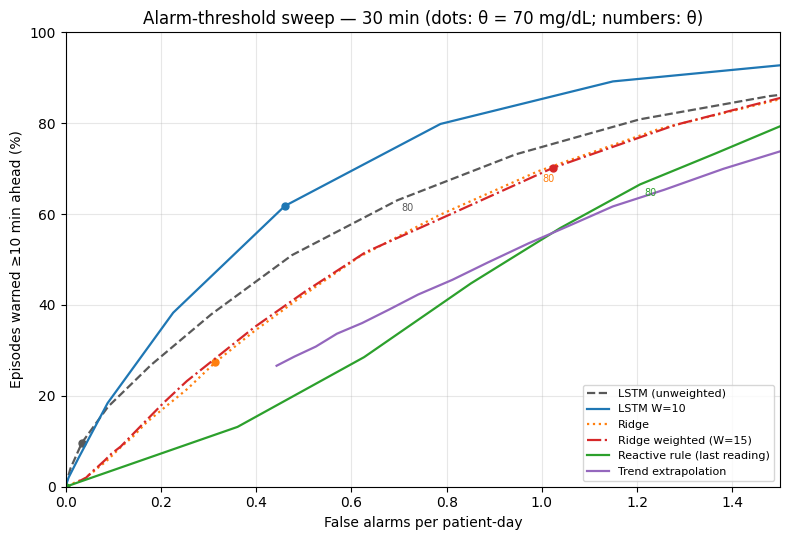

In [28]:
# ---------------------------------------------------------------
# Step I-7 — updated Fig. 2 (detection vs false alarms, 30 min, theta swept 60-130, mean over seeds)
# ---------------------------------------------------------------
FIG_MODELS = {
    'LSTM (unweighted)':               dict(color='0.35', ls='--'),
    f'LSTM W={W_BEST}':                dict(color='tab:blue', ls='-'),
    'Ridge':                           dict(color='tab:orange', ls=':'),
    f'Ridge weighted (W={W_RIDGE})':   dict(color='tab:red', ls='-.'),
    'Reactive rule (last reading)':    dict(color='tab:green', ls='-'),
    'Trend extrapolation':             dict(color='tab:purple', ls='-'),
}
fig, ax = plt.subplots(figsize=(8, 5.5))
i70 = int(np.flatnonzero(THR_I == 70)[0])
for name, st in FIG_MODELS.items():
    if name not in cnt_test:
        continue
    det, fa = curve(cnt_test[name])
    ax.plot(fa, det, lw=1.6, label=name, **st)
    ax.plot(fa[i70], det[i70], 'o', color=st['color'], ms=5)
    for th in (80, 90, 100):
        q = int(np.flatnonzero(THR_I == th)[0])
        if fa[q] <= 1.5:
            ax.annotate(f"{th}", (fa[q], det[q]), fontsize=7, color=st['color'],
                        textcoords='offset points', xytext=(3, -8))
ax.set_xlim(0, 1.5); ax.set_ylim(0, 100)
ax.set_xlabel('False alarms per patient-day'); ax.set_ylabel(f'Episodes warned ≥{WARN_MAIN} min ahead (%)')
ax.set_title(f'Alarm-threshold sweep — {MAIN_HORIZON} min (dots: θ = 70 mg/dL; numbers: θ)')
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'fig_threshold_sweep_v2.png'), dpi=300)
plt.savefig(os.path.join(RESULTS_DIR, 'fig_threshold_sweep_v2.pdf'))
plt.show()

In [ ]:
# ---------------------------------------------------------------
# Step I-8 — fixes after the first Step I results
#   (1) fairer TREND baseline: forecast floored at 40 mg/dL (sensor floor), slope window k and damping
#       tuned on VALIDATION data (so the curve starts at 0 false alarms and is not under-tuned)
#   (2) 1 mg/dL threshold grid (the 2 mg/dL grid made some budget rows land far below the budget)
#   (3) validation-tuned theta table again with the new grid + new trend baseline
#   (4) PAIRED bootstrap CIs at fixed false-alarm rates (differences, not overlapping intervals)
# Needs I-1 ... I-4 to have run (TEST_PRED / VAL_PRED, BOOT_VT, theta_idx_from_val, rates_of).
# ---------------------------------------------------------------
THR_F = np.arange(40, 121, 1)
BUD   = list(FA_LEVELS)                                   # 0.10, 0.25, 0.50 false alarms / patient-day

def trend_pred2(X, pat, damp, k, floor=GLUCOSE_MIN_MGDL):
    g_now, g_back = to_mgdl(ds, X[:, -1, 0], pat), to_mgdl(ds, X[:, -1 - k, 0], pat)
    return np.maximum(g_now + damp * (g_now - g_back) / k * STEPS, floor)

# (1) tune (k, damping) on validation: mean detection over the three false-alarm budgets
grid, score = [(k, d) for k in (3, 6) for d in (0.25, 0.5, 0.75, 1.0)], {}
for k, d in grid:
    c = event_counts_thr2(y_va, t_va, p_va, trend_pred2(dv['X'], p_va, d, k), H_MIN, cur_va, THR_F)
    det, fa = curve(c)
    score[(k, d)] = float(np.mean(np.nan_to_num([det_at_fa(det, fa, f) for f in BUD], nan=0.0)))
K_T, D_T = max(score, key=score.get)
print("trend variants, mean validation detection over FA budgets:")
for (k, d), s in sorted(score.items(), key=lambda x: -x[1]):
    print(f"   k={k} damp={d:<4}  {s:5.1f}" + ("   <- chosen" if (k, d) == (K_T, D_T) else ""))
TREND = f'Trend (k={K_T}, damp={D_T}, tuned on val)'
TEST_PRED[TREND] = [trend_pred2(ds['X_test'], p_te, D_T, K_T)]
VAL_PRED[TREND]  = [trend_pred2(dv['X'], p_va, D_T, K_T)]

# (2)+(3) counts on the 1 mg/dL grid and the validation-tuned table
F_MODELS = ['LSTM (unweighted)', f'LSTM W={W_BEST}', 'Ridge', f'Ridge weighted (W={W_RIDGE})',
            'Reactive rule (last reading)', TREND]
F_MODELS = [m for m in F_MODELS if m in TEST_PRED and m in VAL_PRED]
cF_val  = {m: counts_mean(VAL_PRED[m],  y_va, t_va, p_va, cur_va, THR_F) for m in F_MODELS}
cF_test = {m: counts_mean(TEST_PRED[m], y_te, t_te, p_te, cur_te, THR_F) for m in F_MODELS}

rows = []
for m in F_MODELS:
    det_t, fa_t = curve(cF_test[m]); fa_v = curve(cF_val[m])[1]
    for b in BUD:
        q = theta_idx_from_val(cF_val[m], b)
        bs = np.array([rates_of(cF_test[m][q, i, :]) for i in BOOT_VT])
        (dlo, dhi), (flo, fhi) = ci(bs[:, 0]), ci(bs[:, 1])
        rows.append({'Model': m, 'budget FA/day': b, 'theta (val)': int(THR_F[q]), 'val FA': round(float(fa_v[q]), 3),
                     'test FA [CI]': f"{fa_t[q]:.2f} [{flo:.2f}, {fhi:.2f}]",
                     'test detection % [CI]': f"{det_t[q]:.1f} [{dlo:.1f}, {dhi:.1f}]"})
vt2 = pd.DataFrame(rows)
pd.set_option('display.width', 250)
print("\nTHETA TUNED ON VALIDATION (1 mg/dL grid):")
print(vt2.to_string(index=False))
vt2.to_csv(os.path.join(RESULTS_DIR, 'val_tuned_threshold_results_v2.csv'), index=False)

# (4) paired bootstrap differences at fixed false-alarm rates (each model at its own threshold)
def paired_fixed_fa(cA, cB, f, boot):
    dA, fA = curve(cA); dB, fB = curve(cB)
    est = det_at_fa(dA, fA, f) - det_at_fa(dB, fB, f)
    d = []
    for i in boot:
        a, fa_ = curve(cA[:, i, :]); b, fb_ = curve(cB[:, i, :])
        d.append(det_at_fa(a, fa_, f) - det_at_fa(b, fb_, f))
    lo, hi = ci(d)
    return est, lo, hi

def fmt_pair(est, lo, hi):
    return f"{est:+.1f} [{lo:+.1f}, {hi:+.1f}]" if np.isfinite(est) else "out of range"

wm, um, rm, rwm = f'LSTM W={W_BEST}', 'LSTM (unweighted)', 'Ridge', f'Ridge weighted (W={W_RIDGE})'
PAIRS = [(um, TREND), (wm, TREND), (wm, um), (um, rm), (rwm, rm)]
rows = []
for a, b in PAIRS:
    if a in cF_test and b in cF_test:
        row = {'A minus B': f"{a}  minus  {b}"}
        for f in BUD:
            est, lo, hi = paired_fixed_fa(cF_test[a], cF_test[b], f, BOOT_VT)
            row[f'{f:.2f}/day'] = fmt_pair(est, lo, hi)
        rows.append(row)
pairs_df = pd.DataFrame(rows)
print("\nPAIRED difference in detection (percentage points, 95% patient-bootstrap CI), fixed FA/day:")
print(pairs_df.to_string(index=False))
pairs_df.to_csv(os.path.join(RESULTS_DIR, 'paired_differences_fixed_FA.csv'), index=False)

trend variants, mean validation detection over FA budgets:
   k=3 damp=0.25   30.2   <- chosen
   k=6 damp=0.25   28.1
   k=6 damp=0.5    27.8
   k=3 damp=0.5    25.3
   k=6 damp=0.75   24.1
   k=6 damp=1.0    20.7
   k=3 damp=0.75   20.2
   k=3 damp=1.0    16.6


In [ ]:
# ---------------------------------------------------------------
# Step I-9 — level-2 hypoglycaemia (<54 mg/dL) with paired CIs, ridge-alpha check, LOSO labels
# (the earlier level-2 'matched delta at theta=54' is dropped: it was degenerate)
# ---------------------------------------------------------------
# (a) level 2, 1 mg/dL grid, paired differences at fixed false-alarm rates
THR54F, FA54 = np.arange(40, 111, 1), [0.05, 0.10, 0.25]
L2 = [m for m in [um, wm, rm, 'Reactive rule (last reading)', TREND] if m in TEST_PRED]
c54 = {m: counts_mean(TEST_PRED[m], y_te, t_te, p_te, cur_te, THR54F, thr=54) for m in L2}
print(f"LEVEL 2 (<54 mg/dL): {int(round(c54[um][0, :, 0].sum())):,} test episodes")
print(fixed_fa_table(c54, FA54, BOOT_VT).to_string(index=False))
rows = []
for a, b in [(wm, um), (um, TREND), (wm, TREND)]:
    if a in c54 and b in c54:
        row = {'A minus B': f"{a}  minus  {b}"}
        for f in FA54:
            est, lo, hi = paired_fixed_fa(c54[a], c54[b], f, BOOT_VT)
            row[f'{f:.2f}/day'] = fmt_pair(est, lo, hi)
        rows.append(row)
l2_pairs = pd.DataFrame(rows)
print("\nLevel 2, paired differences (percentage points):")
print(l2_pairs.to_string(index=False))
l2_pairs.to_csv(os.path.join(RESULTS_DIR, 'level2_paired_differences.csv'), index=False)

# (b) ridge alpha was the smallest value of the grid: check a wider grid (report only; nothing is replaced)
f_wide = fit_ridge_w(ds, 1, alphas=(1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0))
rm_wide, _ = evaluate(y_te, f_wide['pred'](ds['X_test'], p_te), p_te)
rm_old, _  = evaluate(y_te, TEST_PRED['Ridge'][0], p_te)
print(f"\nRidge alpha check: grid-edge alpha 0.01 -> test RMSE {rm_old['RMSE']:.3f}; "
      f"wide grid picked alpha={f_wide['alpha']} -> {rm_wide['RMSE']:.3f}. "
      f"If these agree to ~0.01 mg/dL, keep the paper's ridge as is.")

# (c) readable study names for Table III
NAMES = {'RBG': 'ReplaceBG', 'DLCP3': 'DCLP3'}
if 'loso_seeds_df' in globals():
    loso_named = loso_seeds_df.assign(Study=loso_seeds_df['Study'].replace(NAMES))
    loso_named.to_csv(os.path.join(RESULTS_DIR, 'loso_30min_seeds_named.csv'), index=False)
    print("\n", loso_named[['Study', 'Patients']].T.to_string(header=False))

In [ ]:
# ---------------------------------------------------------------
# Step I-10 — Fig. 2 (v3): 1 mg/dL grid, tuned and floored trend baseline
# ---------------------------------------------------------------
FIG_MODELS = {
    um:     dict(color='0.35', ls='--'),
    wm:     dict(color='tab:blue', ls='-'),
    rm:     dict(color='tab:orange', ls=':'),
    rwm:    dict(color='tab:red', ls='-.'),
    'Reactive rule (last reading)': dict(color='tab:green', ls='-'),
    TREND:  dict(color='tab:purple', ls='-'),
}
fig, ax = plt.subplots(figsize=(8, 5.5))
q70 = int(np.flatnonzero(THR_F == 70)[0])
for name, st in FIG_MODELS.items():
    if name not in cF_test:
        continue
    det, fa = curve(cF_test[name])
    ax.plot(fa, det, lw=1.6, label=name, **st)
    ax.plot(fa[q70], det[q70], 'o', color=st['color'], ms=5)
    for th in (80, 90, 100):
        q = int(np.flatnonzero(THR_F == th)[0])
        if fa[q] <= 1.5:
            ax.annotate(f"{th}", (fa[q], det[q]), fontsize=7, color=st['color'],
                        textcoords='offset points', xytext=(3, -8))
ax.set_xlim(0, 1.5); ax.set_ylim(0, 100)
ax.set_xlabel('False alarms per patient-day'); ax.set_ylabel(f'Episodes warned ≥{WARN_MAIN} min ahead (%)')
ax.set_title(f'Alarm-threshold sweep — {MAIN_HORIZON} min (dots: θ = 70 mg/dL; numbers: θ)')
ax.grid(alpha=0.3); ax.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'fig_threshold_sweep_v3.png'), dpi=300)
plt.savefig(os.path.join(RESULTS_DIR, 'fig_threshold_sweep_v3.pdf'))
plt.show()

## Step I-11 / I-12 — refine the trend baseline; check 15 and 60 min
Run in the same kernel after I-1 … I-10. I-11: wider (k, damping) grid tuned on validation (30 min). I-12: trend rule vs stored LSTM / ridge forecasts at 15 and 60 min (no retraining, the 30-min `ds` is not touched).

In [32]:
# ---------------------------------------------------------------
# Step I-11 — refine the trend baseline (30 min): wider (k, damping) grid, tuned on VALIDATION only
# The first grid chose damping 0.25, the smallest value tried. Here: k in {2,3,4,6}, damping 0.1 ... 0.5.
# Forecast = max(current + damp * slope * steps_ahead, 40 mg/dL), slope from the last k readings.
# Needs I-1 ... I-8 in the same kernel.
# ---------------------------------------------------------------
THR_T  = np.arange(50, 101, 2)                  # coarse theta grid, used only to rank variants
KS, DAMPS = (2, 3, 4, 6), (0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5)

def trend_from_hist(G, damp, k, steps, floor=GLUCOSE_MIN_MGDL):
    """G: (n, kmax+1) glucose in mg/dL, last column = current reading."""
    g_now, g_back = G[:, -1], G[:, -1 - k]
    return np.maximum(g_now + damp * (g_now - g_back) / k * steps, floor)

def tune_trend_grid(G, y, t, p, h, steps, ks, damps, thr=THR_T):
    cur, rows = G[:, -1], []
    for k in ks:
        for d in damps:
            c = event_counts_thr2(y, t, p, trend_from_hist(G, d, k, steps), h, cur, thr)
            det, fa = curve(c)
            rows.append((k, d, float(np.mean(np.nan_to_num([det_at_fa(det, fa, f) for f in BUD], nan=0.0)))))
    return pd.DataFrame(rows, columns=['k', 'damp', 'val_score'])

kmax = max(KS)
hist = lambda X, pat: np.stack([to_mgdl(ds, X[:, -1 - j, 0], pat) for j in range(kmax, -1, -1)], axis=1)
G_va, G_te = hist(dv['X'], p_va), hist(ds['X_test'], p_te)

tg = tune_trend_grid(G_va, y_va, t_va, p_va, H_MIN, STEPS, KS, DAMPS)
print("Validation score (mean detection % over the FA budgets), rows = k, columns = damping:")
print(tg.pivot(index='k', columns='damp', values='val_score').round(1).to_string())
best = tg.loc[tg['val_score'].idxmax()]
K2, D2 = int(best['k']), float(best['damp'])
old = float(tg[(tg['k'] == 3) & (tg['damp'] == 0.25)]['val_score'].iloc[0])
print(f"\nBest: k={K2}, damping={D2} (score {best['val_score']:.1f}); previous choice k=3, damping=0.25 scored {old:.1f}")
if K2 in (min(KS), max(KS)) or D2 in (min(DAMPS), max(DAMPS)):
    print("WARNING: the best variant is on the edge of the grid -> extend the grid in that direction.")
tg.to_csv(os.path.join(RESULTS_DIR, 'trend_grid_30min_validation.csv'), index=False)

# evaluate the refined rule exactly as in I-8 (theta from validation, 1 mg/dL grid)
TREND2 = f'Trend2 (k={K2}, damp={D2}, tuned on val)'
TEST_PRED[TREND2] = [trend_from_hist(G_te, D2, K2, STEPS)]
VAL_PRED[TREND2]  = [trend_from_hist(G_va, D2, K2, STEPS)]
cF_val[TREND2]  = counts_mean(VAL_PRED[TREND2],  y_va, t_va, p_va, cur_va, THR_F)
cF_test[TREND2] = counts_mean(TEST_PRED[TREND2], y_te, t_te, p_te, cur_te, THR_F)

det_t, fa_t = curve(cF_test[TREND2]); fa_v = curve(cF_val[TREND2])[1]
rows = []
for b in BUD:
    q = theta_idx_from_val(cF_val[TREND2], b)
    bs = np.array([rates_of(cF_test[TREND2][q, i, :]) for i in BOOT_VT])
    (dlo, dhi), (flo, fhi) = ci(bs[:, 0]), ci(bs[:, 1])
    rows.append({'budget FA/day': b, 'theta (val)': int(THR_F[q]), 'val FA': round(float(fa_v[q]), 3),
                 'test FA [CI]': f"{fa_t[q]:.2f} [{flo:.2f}, {fhi:.2f}]",
                 'test detection % [CI]': f"{det_t[q]:.1f} [{dlo:.1f}, {dhi:.1f}]"})
print(f"\n{TREND2} — theta tuned on validation:")
print(pd.DataFrame(rows).to_string(index=False))

rows = []
for a, b_ in [(um, TREND2), (wm, TREND2), (um, TREND), (wm, TREND)]:
    row = {'A minus B': f"{a}  minus  {b_}"}
    for f in BUD:
        row[f'{f:.2f}/day'] = fmt_pair(*paired_fixed_fa(cF_test[a], cF_test[b_], f, BOOT_VT))
    rows.append(row)
pairs2 = pd.DataFrame(rows)
print("\nPaired differences (percentage points, 95% patient-bootstrap CI); the old rule is shown for reference:")
print(pairs2.to_string(index=False))
pairs2.to_csv(os.path.join(RESULTS_DIR, 'paired_differences_trend_refined.csv'), index=False)


Paired differences (percentage points, 95% patient-bootstrap CI); the old rule is shown for reference:
                                                     A minus B            0.10/day             0.25/day           0.50/day
LSTM (unweighted)  minus  Trend2 (k=4, damp=0.3, tuned on val)  +9.5 [+7.0, +12.1]   +6.8 [+2.7, +10.7]  -4.5 [-8.4, -0.2]
        LSTM W=10  minus  Trend2 (k=4, damp=0.3, tuned on val) +11.0 [+7.9, +14.3] +14.9 [+11.2, +18.6] +7.3 [+4.1, +11.0]
LSTM (unweighted)  minus  Trend (k=3, damp=0.25, tuned on val) +10.6 [+8.2, +13.2]   +7.2 [+3.4, +11.0]  -6.2 [-9.6, -2.5]
        LSTM W=10  minus  Trend (k=3, damp=0.25, tuned on val) +12.1 [+9.0, +15.5] +15.3 [+11.7, +18.9]  +5.7 [+2.8, +8.5]


In [33]:
# ---------------------------------------------------------------
# Step I-12 — does the picture hold at 15 and 60 min?  (trend rule vs the stored LSTM / ridge forecasts)
# * the rule is re-tuned on VALIDATION data of each horizon (same grid as I-11)
# * stored test forecasts of Step D are used for ridge and for the LSTMs (W=1 and W_BEST, level target, 3 seeds)
# * LSTM / ridge have no stored validation forecasts at these horizons, so this comparison takes every
#   model at its own threshold matched on the TEST curve (like the old Table II): optimistic for all
#   models alike, and fair between them. No retraining; the 30-min `ds` is NOT touched.
# Needs I-1 ... I-11 (helpers) in the same kernel.
# ---------------------------------------------------------------
def light_windows(steps, kmax):
    """Test windows and dense validation windows for another horizon (same rules as build_dataset /
    build_val_dense), keeping only the last kmax+1 glucose values in mg/dL instead of full windows."""
    offs = np.arange(-kmax, 1)
    G_, y_, t_, p_ = {'test': [], 'val': []}, {'test': [], 'val': []}, {'test': [], 'val': []}, {'test': [], 'val': []}
    k_idx = -1
    for pid, pdata in df_raw.groupby('PtID', sort=False):
        pdata = pdata.sort_values('Time')
        valid = pdata[feature_columns].notna().all(axis=1)
        if valid.sum() < MIN_READINGS:
            continue
        cutoff = pdata.loc[valid, 'Time'].iloc[int(valid.sum() * TRAIN_RATIO)]
        is_tr = (pdata['Time'] < cutoff).values
        Xa = pdata[feature_columns].values                    # unscaled: same NaN pattern as the scaled windows
        gl = pdata[target_column].values.astype(np.float64)
        real = pdata['Is_real'].values
        tmin = pdata['Time'].values.astype('datetime64[m]').astype(np.int64)
        block = pdata['Seg'].astype(str).values + np.where(is_tr, '_tr', '_te')
        starts = np.r_[0, np.flatnonzero(block[1:] != block[:-1]) + 1, len(block)]
        t_tr, te = [], []
        for a, b in zip(starts[:-1], starts[1:]):
            if is_tr[a]:
                _, _, tp = make_windows(Xa[a:b], gl[a:b], real[a:b], SEQ_LENGTH, steps, TRAIN_STRIDE, False)
                if tp is not None:
                    t_tr.append(tmin[a:b][tp])
            else:
                _, _, tp = make_windows(Xa[a:b], gl[a:b], real[a:b], SEQ_LENGTH, steps, 1, True)
                if tp is not None:
                    pos = tp - steps                          # row of the last input reading
                    te.append((gl[a:b][pos[:, None] + offs[None, :]], gl[a:b][tp], tmin[a:b][tp]))
        if not t_tr or not te:                                # same inclusion rule as build_dataset
            continue
        k_idx += 1
        for Gx, yx, tx in te:
            G_['test'].append(Gx); y_['test'].append(yx); t_['test'].append(tx)
            p_['test'].append(np.full(len(yx), k_idx, np.int32))
        t_tr = np.concatenate(t_tr)
        t_val0 = t_tr[int(len(t_tr) * (1 - VAL_RATIO))]
        for a, b in zip(starts[:-1], starts[1:]):
            if not is_tr[a]:
                continue
            s = max(0, int(np.searchsorted(tmin[a:b], t_val0, 'left')) - (SEQ_LENGTH + steps - 1))
            if b - a - s < SEQ_LENGTH + steps:
                continue
            _, _, tp = make_windows(Xa[a + s:b], gl[a + s:b], real[a + s:b], SEQ_LENGTH, steps, 1, True)
            if tp is None:
                continue
            td = tmin[a + s:b][tp]; keep = td >= t_val0
            if keep.any():
                pos = (tp - steps)[keep]
                G_['val'].append(gl[a + s:b][pos[:, None] + offs[None, :]])
                y_['val'].append(gl[a + s:b][tp[keep]]); t_['val'].append(td[keep])
                p_['val'].append(np.full(int(keep.sum()), k_idx, np.int32))
    return {s: tuple(np.concatenate(v[s]) for v in (G_, y_, t_, p_)) for s in ('test', 'val')}

H_OTHER, HZ_TABLES = [h for h in HORIZONS if h != MAIN_HORIZON], {}
for h in H_OTHER:
    steps = HORIZONS[h]
    print(f"\n================ {h}-min horizon ================")
    lw = light_windows(steps, max(KS))
    Gte, yte, tte, pte = lw['test']; Gva, yva, tva, pva = lw['val']
    # consistency with the files written in Step D
    f = lambda n: np.load(os.path.join(RESULTS_DIR, n))
    assert np.array_equal(tte, f(f"t_test_h{h}.npy")) and np.array_equal(pte, f(f"p_test_h{h}.npy")), "test windows differ from Step D"
    assert np.allclose(yte, f(f"y_test_mgdl_h{h}.npy"), atol=1e-2)
    pers = np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_Persistence.npz"))['y_pred']
    assert np.allclose(pers, Gte[:, -1], atol=1e-2), "current glucose differs from the persistence forecast"
    print(f"test windows {len(yte):,} | dense validation windows {len(yva):,} | consistent with Step D files")

    tgh = tune_trend_grid(Gva, yva, tva, pva, h, steps, KS, DAMPS)
    bh = tgh.loc[tgh['val_score'].idxmax()]; kh, dh = int(bh['k']), float(bh['damp'])
    print(tgh.pivot(index='k', columns='damp', values='val_score').round(1).to_string())
    print(f"chosen on validation: k={kh}, damping={dh}" +
          ("   (WARNING: grid edge)" if kh in (min(KS), max(KS)) or dh in (min(DAMPS), max(DAMPS)) else ""))
    tgh.to_csv(os.path.join(RESULTS_DIR, f'trend_grid_{h}min_validation.csv'), index=False)

    ld = lambda W: [np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_LSTM_level_W{W}_s{s}.npz"))['y_pred'] for s in SEEDS]
    TR = f'Trend (k={kh}, damp={dh})'
    P = {um: ld(1), wm: ld(W_BEST), rm: [np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_Ridge.npz"))['y_pred']],
         'Reactive rule (last reading)': [Gte[:, -1]], TR: [trend_from_hist(Gte, dh, kh, steps)]}
    cnt = {m: np.mean([event_counts_thr2(yte, tte, pte, yp, h, Gte[:, -1], THR_F) for yp in v], axis=0) for m, v in P.items()}
    boot = boot_index(next(iter(cnt.values())).shape[1])
    print(f"\n{h} min — episodes warned >=10 min ahead (%) at fixed false-alarm rates [95% CI], each model at its own theta:")
    tab = fixed_fa_table(cnt, BUD, boot); print(tab.to_string(index=False))
    rows = []
    for a, b_ in [(um, TR), (wm, TR), (wm, um), (um, rm)]:
        row = {'A minus B': f"{a}  minus  {b_}"}
        for fa_level in BUD:
            row[f'{fa_level:.2f}/day'] = fmt_pair(*paired_fixed_fa(cnt[a], cnt[b_], fa_level, boot))
        rows.append(row)
    pr = pd.DataFrame(rows)
    print(f"\n{h} min — paired differences (percentage points):"); print(pr.to_string(index=False))
    tab.to_csv(os.path.join(RESULTS_DIR, f'fixed_FA_with_trend_{h}min.csv'), index=False)
    pr.to_csv(os.path.join(RESULTS_DIR, f'paired_with_trend_{h}min.csv'), index=False)
    HZ_TABLES[h] = (tab, pr)
    del lw, Gte, Gva, cnt; gc.collect()


================ 15-min horizon ================
test windows 1,739,265 | dense validation windows 1,398,588 | consistent with Step D files
damp  0.10  0.15  0.20  0.25  0.30  0.40  0.50
k                                             
2     15.7  18.3  20.6  23.0  24.8  26.7  27.2
3     15.0  17.0  19.7  22.1  24.1  26.5  28.0
4     14.3  16.7  18.8  21.0  23.3  26.0  28.1
6     12.7  14.3  16.2  18.3  20.3  23.4  26.2
chosen on validation: k=4, damping=0.5   (WARNING: grid edge)

15 min — episodes warned >=10 min ahead (%) at fixed false-alarm rates [95% CI], each model at its own theta:
 FA/day LSTM (unweighted)         LSTM W=10             Ridge Reactive rule (last reading) Trend (k=4, damp=0.5)
   0.10 17.6 [15.0, 20.8] 16.0 [13.1, 19.5]    6.2 [4.9, 8.4]               2.6 [2.2, 3.1]        8.0 [6.5, 9.5]
   0.25 40.6 [36.1, 45.8] 39.1 [34.2, 44.7] 22.4 [18.4, 27.7]               6.5 [5.4, 7.9]     24.1 [20.3, 28.9]
   0.50 65.0 [60.5, 69.9] 66.4 [61.3, 72.2] 51.5 [45.6, 58.0]    

In [34]:
# ---------------------------------------------------------------
# Step I-13 — is the comparison fair on ALARM BURDEN, not only on false-alarm episodes?   (15, 30, 60 min)
# "False alarms per day" counts alarm EPISODES (alarms <= 15 min apart are merged) and calls an episode true if
# a low follows within (horizon + 15) min of its end. A rule that stays in alarm for long stretches can look
# good on that measure while being in alarm for hours. This cell adds:
#   A) an operating-point table (lenient FA budget 0.5/day, theta matched on test): detection, lenient AND
#      strict false alarms, alarm episodes/day, % of time in alarm, hours in alarm/day, median warning time
#   B) detection at fixed TIME IN ALARM (hours/patient-day) with patient-bootstrap CIs and paired differences
# 15 min: the trend damping grid is extended to 0.75 and 1.0 (it chose the old grid edge 0.5).
# Needs I-1 ... I-12 in the same kernel (light_windows, tune_trend_grid, ... come from I-11 / I-12).
# ---------------------------------------------------------------
def _onsets(y, tt, thr, min_len=3, merge_gap=30):
    low = y < thr
    brk = np.r_[True, ~(low[1:] & low[:-1] & (np.diff(tt) == 5))]
    run_id = np.cumsum(brk)
    onsets, ends = [], []
    for r in np.unique(run_id[low]):
        idx = np.flatnonzero((run_id == r) & low)
        if len(idx) >= min_len:
            if onsets and tt[idx[0]] - ends[-1] < merge_gap:
                ends[-1] = tt[idx[-1]]
            else:
                onsets.append(tt[idx[0]]); ends.append(tt[idx[-1]])
    return np.array(onsets, dtype=np.int64), low

def event_counts_time(y_true, t, pat, y_pred, h, current, thresholds, thr=70):
    """Per threshold and patient: [events, detected >= WARN_MAIN, alarm steps (5-min), windows]."""
    bounds = np.r_[0, np.flatnonzero(np.diff(pat)) + 1, len(pat)]
    out = np.zeros((len(thresholds), len(bounds) - 1, 4))
    for k, (a, b) in enumerate(zip(bounds[:-1], bounds[1:])):
        y, tt, yp, cur = y_true[a:b], t[a:b], y_pred[a:b], current[a:b]
        onsets, _ = _onsets(y, tt, thr)
        ok_cur = cur >= thr
        for q, th in enumerate(thresholds):
            al = (yp < th) & ok_cur
            s_al = tt[al] - h
            d10 = 0
            if len(s_al) and len(onsets):
                i = np.searchsorted(s_al, onsets - h - 15, 'left'); j = np.searchsorted(s_al, onsets, 'right')
                lead = np.where(j > i, onsets - s_al[np.minimum(i, len(s_al) - 1)], -1)
                d10 = int(np.sum(lead >= WARN_MAIN))
            out[q, k] = [len(onsets), d10, int(al.sum()), b - a]
    return out

def curve_time(c):
    """(n_thr, n_pat, 4) -> detection % and hours in alarm per patient-day, per threshold."""
    tot = c.sum(axis=1)
    return 100 * tot[:, 1] / np.maximum(tot[:, 0], 1), 24 * tot[:, 2] / np.maximum(tot[:, 3], 1)

def event_detail(y_true, t, pat, y_pred, h, current, theta, thr=70):
    bounds = np.r_[0, np.flatnonzero(np.diff(pat)) + 1, len(pat)]
    r = dict(events=0, det=0, steps=0, windows=0, eps=0, fa_len=0, fa_str=0); leads_ok = []
    for a, b in zip(bounds[:-1], bounds[1:]):
        y, tt, yp, cur = y_true[a:b], t[a:b], y_pred[a:b], current[a:b]
        onsets, low = _onsets(y, tt, thr)
        al = (yp < theta) & (cur >= thr); s_al = tt[al] - h
        r['events'] += len(onsets); r['steps'] += int(al.sum()); r['windows'] += b - a
        if not len(s_al):
            continue
        if len(onsets):
            i = np.searchsorted(s_al, onsets - h - 15, 'left'); j = np.searchsorted(s_al, onsets, 'right')
            lead = np.where(j > i, onsets - s_al[np.minimum(i, len(s_al) - 1)], -1)
            r['det'] += int(np.sum(lead >= WARN_MAIN)); leads_ok += list(lead[lead >= WARN_MAIN])
        ep = np.r_[0, np.flatnonzero(np.diff(s_al) > 15) + 1, len(s_al)]
        s0, s1 = s_al[ep[:-1]], s_al[ep[1:] - 1]; lt = tt[low]
        lo = np.searchsorted(lt, s0, 'left')
        r['eps'] += len(s0)
        r['fa_len'] += int(np.sum(lo >= np.searchsorted(lt, s1 + h + 15, 'right')))
        r['fa_str'] += int(np.sum(lo >= np.searchsorted(lt, s0 + h + 15, 'right')))
    r['median_warning'] = float(np.median(leads_ok)) if leads_ok else np.nan
    return r

def fixed_x_table(counts, levels, boot, label):
    cv = {m: curve_time(c) for m, c in counts.items()}
    bt = {m: [curve_time(c[:, i, :]) for i in boot] for m, c in counts.items()}
    rows = []
    for f in levels:
        row = {label: round(float(f), 2)}
        for m in counts:
            est = det_at_fa(*cv[m], f)
            lo, hi = ci([det_at_fa(d, x, f) for d, x in bt[m]])
            row[m] = f"{est:.1f} [{lo:.1f}, {hi:.1f}]" if np.isfinite(est) else "out of range"
        rows.append(row)
    return pd.DataFrame(rows)

def paired_x(cA, cB, f, boot):
    est = det_at_fa(*curve_time(cA), f) - det_at_fa(*curve_time(cB), f)
    d = [det_at_fa(*curve_time(cA[:, i, :]), f) - det_at_fa(*curve_time(cB[:, i, :]), f) for i in boot]
    lo, hi = ci(d); return est, lo, hi

RULE, REACT = 'Trend rule (tuned on val)', 'Reactive rule (last reading)'
STEP_X = 1                     # 1 = 1 mg/dL theta grid (slowest, ~30-40 min in total); 2 = half the time
THR_X = THR_F[::STEP_X]
OP_BUDGET = 0.5
ALARM_TABLES = {}
for h in (15, MAIN_HORIZON, 60):
    print(f"\n================ {h}-min horizon ================")
    if h == MAIN_HORIZON:
        y_h, t_h, p_h, cur_h = y_te, t_te, p_te, cur_te
        P = {um: TEST_PRED[um], wm: TEST_PRED[wm], rm: TEST_PRED['Ridge'], REACT: [cur_te], RULE: TEST_PRED[TREND2]}
        print(f"trend rule: k={K2}, damping={D2} (I-11)")
    else:
        steps = HORIZONS[h]
        lw = light_windows(steps, max(KS))
        Gte, y_h, t_h, p_h = lw['test']; cur_h = Gte[:, -1]
        assert np.array_equal(t_h, np.load(os.path.join(RESULTS_DIR, f"t_test_h{h}.npy"))), "test windows differ from Step D"
        if h == 15:
            Gva, yva, tva, pva = lw['val']
            damps = tuple(DAMPS) + (0.75, 1.0)
            tgh = tune_trend_grid(Gva, yva, tva, pva, h, steps, KS, damps)
            tgh.to_csv(os.path.join(RESULTS_DIR, 'trend_grid_15min_validation_extended.csv'), index=False)
            print(tgh.pivot(index='k', columns='damp', values='val_score').round(1).to_string())
            b = tgh.loc[tgh['val_score'].idxmax()]; kh, dh = int(b['k']), float(b['damp'])
            if dh == max(damps) or kh in (min(KS), max(KS)):
                print("WARNING: the best 15-min variant is still on the edge of the grid")
        else:
            tgh = pd.read_csv(os.path.join(RESULTS_DIR, f'trend_grid_{h}min_validation.csv'))
            b = tgh.loc[tgh['val_score'].idxmax()]; kh, dh = int(b['k']), float(b['damp'])
        print(f"trend rule: k={kh}, damping={dh}")
        ld = lambda W: [np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_LSTM_level_W{W}_s{s}.npz"))['y_pred'] for s in SEEDS]
        P = {um: ld(1), wm: ld(W_BEST), rm: [np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_Ridge.npz"))['y_pred']],
             REACT: [cur_h], RULE: [trend_from_hist(Gte, dh, kh, steps)]}
        del lw, Gte
    # ---- A) operating point: largest theta with lenient FA <= OP_BUDGET on the test curve
    rows, theta_op = [], {}
    for m, preds in P.items():
        c_len = np.mean([event_counts_thr2(y_h, t_h, p_h, yp, h, cur_h, THR_X) for yp in preds], axis=0)
        q = theta_idx_from_val(c_len, OP_BUDGET); theta_op[m] = int(THR_X[q])
        d = [event_detail(y_h, t_h, p_h, yp, h, cur_h, THR_X[q]) for yp in preds]
        avg = lambda key: float(np.mean([x[key] for x in d]))
        days = avg('windows') * 5 / 1440
        rows.append({'Model': m, 'theta': theta_op[m], 'detected %': round(100 * avg('det') / avg('events'), 1),
                     'FA/day (lenient)': round(avg('fa_len') / days, 2), 'FA/day (strict)': round(avg('fa_str') / days, 2),
                     'alarm episodes/day': round(avg('eps') / days, 2),
                     '% time in alarm': round(100 * avg('steps') / avg('windows'), 2),
                     'hours in alarm/day': round(24 * avg('steps') / avg('windows'), 2),
                     'median warning (min)': round(float(np.nanmean([x['median_warning'] for x in d])), 1)})
    tabA = pd.DataFrame(rows)
    print(f"\n{h} min — A) operating point (theta: lenient FA <= {OP_BUDGET}/day on the test set):")
    print(tabA.to_string(index=False))
    # ---- B) detection at fixed time in alarm
    cnt = {m: np.mean([event_counts_time(y_h, t_h, p_h, yp, h, cur_h, THR_X) for yp in preds], axis=0) for m, preds in P.items()}
    boot = boot_index(next(iter(cnt.values())).shape[1])
    x_ref = float(tabA.loc[tabA['Model'] == wm, 'hours in alarm/day'].iloc[0])      # weighted LSTM's alarm time at the operating point
    levels = [round(x_ref * k, 2) for k in (0.5, 1.0, 2.0)]
    tabB = fixed_x_table(cnt, levels, boot, 'hours in alarm/day')
    print(f"\n{h} min — B) episodes warned >=10 min ahead (%) at fixed time in alarm [95% CI]:")
    print(tabB.to_string(index=False))
    rows = []
    for a_, b_ in [(um, RULE), (wm, RULE), (wm, um)]:
        row = {'A minus B': f"{a_}  minus  {b_}"}
        for f in levels:
            row[f'{f:.2f} h/day'] = fmt_pair(*paired_x(cnt[a_], cnt[b_], f, boot))
        rows.append(row)
    pairB = pd.DataFrame(rows)
    print(f"\n{h} min — B) paired differences at fixed time in alarm (percentage points):"); print(pairB.to_string(index=False))
    tabA.to_csv(os.path.join(RESULTS_DIR, f'alarm_burden_operating_point_{h}min.csv'), index=False)
    tabB.to_csv(os.path.join(RESULTS_DIR, f'alarm_time_matched_{h}min.csv'), index=False)
    pairB.to_csv(os.path.join(RESULTS_DIR, f'alarm_time_paired_{h}min.csv'), index=False)
    ALARM_TABLES[h] = (tabA, tabB, pairB)
    del cnt; gc.collect()


================ 15-min horizon ================
damp  0.10  0.15  0.20  0.25  0.30  0.40  0.50  0.75  1.00
k                                                         
2     15.7  18.3  20.6  23.0  24.8  26.7  27.2  24.6  19.3
3     15.0  17.0  19.7  22.1  24.1  26.5  28.0  26.4  20.9
4     14.3  16.7  18.8  21.0  23.3  26.0  28.1  27.6  22.2
6     12.7  14.3  16.2  18.3  20.3  23.4  26.2  27.2  22.8
trend rule: k=4, damping=0.5

15 min — A) operating point (theta: lenient FA <= 0.5/day on the test set):
                       Model  theta  detected %  FA/day (lenient)  FA/day (strict)  alarm episodes/day  % time in alarm  hours in alarm/day  median warning (min)
           LSTM (unweighted)     73        61.6              0.45             0.47                1.30             0.81                0.20                  15.0
                   LSTM W=10     70        59.9              0.42             0.43                1.30             0.74                0.18                  10.0
    

In [35]:
# ---------------------------------------------------------------
# Step I-14 — how much WARNING TIME does each method give?  + paired CIs on the time-in-alarm measure
#   A) detection when the required warning is 10 / 15 / 20 / 30 / 45 min, at the I-13 operating points
#      (theta per model = largest theta with lenient FA <= 0.5/day on test, taken from I-13), 95% patient CI
#   B) paired differences in detection at fixed TIME IN ALARM for two required warnings, so the corrected
#      statements about ridge and the trend rule have confidence intervals
# Needs I-13 to have run in the same kernel (ALARM_TABLES, THR_X, RULE) and I-11 / I-12 helpers.
# ---------------------------------------------------------------
assert 'ALARM_TABLES' in globals(), "run I-13 first"
WARNS    = (10, 15, 20, 30, 45)
SHOW_W   = {15: (10, 15, 20), 30: (10, 15, 20, 30), 60: (10, 20, 30, 45)}     # warnings that make sense per horizon
PAIR_W   = {15: (10, 15), 30: (10, 20), 60: (10, 30)}                         # required warnings used for the paired tables

def event_counts_time_w(y_true, t, pat, y_pred, h, current, thresholds, thr=70):
    """Per threshold and patient: [events, detected at each warning in WARNS..., alarm steps, windows]."""
    bounds = np.r_[0, np.flatnonzero(np.diff(pat)) + 1, len(pat)]
    out = np.zeros((len(thresholds), len(bounds) - 1, 3 + len(WARNS)))
    for k, (a, b) in enumerate(zip(bounds[:-1], bounds[1:])):
        y, tt, yp, cur = y_true[a:b], t[a:b], y_pred[a:b], current[a:b]
        onsets, _ = _onsets(y, tt, thr)
        ok_cur = cur >= thr
        for q, th in enumerate(thresholds):
            al = (yp < th) & ok_cur
            s_al = tt[al] - h
            det = np.zeros(len(WARNS))
            if len(s_al) and len(onsets):
                i = np.searchsorted(s_al, onsets - h - 15, 'left'); j = np.searchsorted(s_al, onsets, 'right')
                lead = np.where(j > i, onsets - s_al[np.minimum(i, len(s_al) - 1)], -1)
                det = np.array([np.sum(lead >= w) for w in WARNS], float)
            out[q, k] = np.r_[len(onsets), det, int(al.sum()), b - a]
    return out

def curve_w(c, j):
    tot = c.sum(axis=1)
    return 100 * tot[:, 1 + j] / np.maximum(tot[:, 0], 1), 24 * tot[:, -2] / np.maximum(tot[:, -1], 1)

def paired_w(cA, cB, f, j, boot):
    est = det_at_fa(*curve_w(cA, j), f) - det_at_fa(*curve_w(cB, j), f)
    d = [det_at_fa(*curve_w(cA[:, i, :], j), f) - det_at_fa(*curve_w(cB[:, i, :], j), f) for i in boot]
    lo, hi = ci(d); return est, lo, hi

def load_for(h):
    if h == MAIN_HORIZON:
        return y_te, t_te, p_te, cur_te, {um: TEST_PRED[um], wm: TEST_PRED[wm], rm: TEST_PRED['Ridge'], RULE: TEST_PRED[TREND2]}
    steps = HORIZONS[h]
    lw = light_windows(steps, max(KS)); Gte, y_h, t_h, p_h = lw['test']
    assert np.array_equal(t_h, np.load(os.path.join(RESULTS_DIR, f"t_test_h{h}.npy"))), "test windows differ from Step D"
    f_csv = 'trend_grid_15min_validation_extended.csv' if h == 15 else f'trend_grid_{h}min_validation.csv'
    tg_ = pd.read_csv(os.path.join(RESULTS_DIR, f_csv)); b = tg_.loc[tg_['val_score'].idxmax()]
    kh, dh = int(b['k']), float(b['damp'])
    ld = lambda W: [np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_LSTM_level_W{W}_s{s}.npz"))['y_pred'] for s in SEEDS]
    P = {um: ld(1), wm: ld(W_BEST), rm: [np.load(os.path.join(RESULTS_DIR, 'preds', f"h{h}_Ridge.npz"))['y_pred']],
         RULE: [trend_from_hist(Gte, dh, kh, steps)]}
    print(f"trend rule: k={kh}, damping={dh}")
    return y_h, t_h, p_h, Gte[:, -1], P

WARN_TABLES = {}
for h in (15, MAIN_HORIZON, 60):
    print(f"\n================ {h}-min horizon ================")
    y_h, t_h, p_h, cur_h, P = load_for(h)
    tabA = ALARM_TABLES[h][0]; theta = dict(zip(tabA['Model'], tabA['theta']))
    cnt = {m: np.mean([event_counts_time_w(y_h, t_h, p_h, yp, h, cur_h, THR_X) for yp in preds], axis=0) for m, preds in P.items()}
    boot = boot_index(next(iter(cnt.values())).shape[1])
    # ---- A) detection vs required warning time at the operating points
    rows = []
    for m, c in cnt.items():
        q = int(np.flatnonzero(THR_X == theta[m])[0])
        row = {'Model': m, 'theta': int(theta[m])}
        for j, w in enumerate(WARNS):
            if w not in SHOW_W[h]:
                continue
            est = 100 * c[q, :, 1 + j].sum() / max(c[q, :, 0].sum(), 1)
            lo, hi = ci([100 * c[q, i, 1 + j].sum() / max(c[q, i, 0].sum(), 1) for i in boot])
            row[f'warning >= {w} min'] = f"{est:.1f} [{lo:.1f}, {hi:.1f}]"
        rows.append(row)
    tA = pd.DataFrame(rows)
    print(f"\n{h} min — A) episodes detected (%) by required warning time, operating points of I-13 (95% CI):")
    print(tA.to_string(index=False))
    # ---- B) paired differences at fixed time in alarm
    x_ref = float(tabA.loc[tabA['Model'] == wm, 'hours in alarm/day'].iloc[0])
    levels = [round(x_ref * k_, 2) for k_ in (0.5, 1.0, 2.0)]
    blocks = []
    for w in PAIR_W[h]:
        j = WARNS.index(w); rows = []
        for a_, b_ in [(wm, rm), (um, rm), (wm, RULE), (wm, um)]:
            row = {'required warning': f">= {w} min", 'A minus B': f"{a_}  minus  {b_}"}
            for f in levels:
                row[f'{f:.2f} h/day'] = fmt_pair(*paired_w(cnt[a_], cnt[b_], f, j, boot))
            rows.append(row)
        blocks.append(pd.DataFrame(rows))
    tB = pd.concat(blocks, ignore_index=True)
    print(f"\n{h} min — B) paired differences in detection (percentage points) at fixed time in alarm:")
    print(tB.to_string(index=False))
    tA.to_csv(os.path.join(RESULTS_DIR, f'warning_time_operating_point_{h}min.csv'), index=False)
    tB.to_csv(os.path.join(RESULTS_DIR, f'warning_time_paired_{h}min.csv'), index=False)
    WARN_TABLES[h] = (tA, tB)
    del cnt; gc.collect()


================ 15-min horizon ================
trend rule: k=4, damping=0.5

15 min — A) episodes detected (%) by required warning time, operating points of I-13 (95% CI):
                    Model  theta warning >= 10 min warning >= 15 min warning >= 20 min
        LSTM (unweighted)     73 61.6 [58.4, 64.9] 32.0 [29.5, 34.6] 16.6 [14.9, 18.3]
                LSTM W=10     70 59.9 [57.8, 61.9] 27.1 [25.6, 28.7] 12.7 [11.7, 13.8]
                    Ridge     73 45.9 [43.6, 48.1] 19.8 [18.3, 21.1]   9.7 [8.7, 10.7]
Trend rule (tuned on val)     70 52.2 [50.5, 53.9] 23.6 [22.3, 24.8] 12.4 [11.5, 13.3]

15 min — B) paired differences in detection (percentage points) at fixed time in alarm:
required warning                                   A minus B           0.09 h/day           0.18 h/day           0.36 h/day
       >= 10 min                     LSTM W=10  minus  Ridge    +5.6 [+4.4, +7.1]    +7.6 [+6.1, +8.6]    +1.2 [+0.1, +2.2]
       >= 10 min             LSTM (unweighted)  minus

In [36]:
import os
import pandas as pd

print("Dataset exists:", os.path.exists(MAIN_DB_FILE))
print("Dataset path:", MAIN_DB_FILE)

if os.path.exists(MAIN_DB_FILE):
    df = pd.read_csv(MAIN_DB_FILE, nrows=5)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nSample:")
    print(df.head())

    print("\nFile size (GB):",
          round(os.path.getsize(MAIN_DB_FILE) / 1e9, 3))

Dataset exists: True
Dataset path: D:\Dataset\DiaData2026\5_min_sampling\raw\raw\MDB_5min_sampling_raw\MDB_5min_sampling_raw.csv

Columns:
['ts', 'PtID', 'GlucoseCGM', 'Database']

Sample:
                              ts        PtID  GlucoseCGM Database
0  2014-10-01T19:15:00.000000000  001_D1NAMO     185.606   D1NAMO
1  2014-10-01T19:20:00.000000000  001_D1NAMO     178.398   D1NAMO
2  2014-10-01T19:25:00.000000000  001_D1NAMO         NaN   D1NAMO
3  2014-10-01T19:30:00.000000000  001_D1NAMO     172.992   D1NAMO
4  2014-10-01T19:35:00.000000000  001_D1NAMO     169.388   D1NAMO

File size (GB): 6.929


In [37]:

import pandas as pd
import os

file_path = MAIN_DB_FILE

# Read the dataset in chunks
chunk_size = 500_000

total_rows = 0
missing_glucose = 0
patient_ids = set()
studies = set()
duplicate_rows = 0
glucose_min = float("inf")
glucose_max = float("-inf")

for chunk in pd.read_csv(file_path, chunksize=chunk_size):

    total_rows += len(chunk)

    missing_glucose += chunk["GlucoseCGM"].isna().sum()

    patient_ids.update(chunk["PtID"].dropna().unique())
    studies.update(chunk["Database"].dropna().unique())

    duplicate_rows += chunk.duplicated().sum()

    valid = chunk["GlucoseCGM"].dropna()

    if len(valid):
        glucose_min = min(glucose_min, valid.min())
        glucose_max = max(glucose_max, valid.max())

print("TOTAL ROWS:", total_rows)
print("UNIQUE PATIENTS:", len(patient_ids))
print("UNIQUE STUDIES:", len(studies))
print("STUDY NAMES:", sorted(studies))
print("MISSING GLUCOSE:", missing_glucose)
print("MISSING GLUCOSE (%):",
      round(missing_glucose / total_rows * 100, 2))
print("DUPLICATE ROWS:", duplicate_rows)
print("MIN GLUCOSE:", glucose_min)
print("MAX GLUCOSE:", glucose_max)


TOTAL ROWS: 135121592
UNIQUE PATIENTS: 1720
UNIQUE STUDIES: 13
STUDY NAMES: ['CITY', 'D1NAMO', 'DDATSHR', 'DLCP3', 'HUPA-UCM', 'PEDAP', 'RBG', 'RT-CGM', 'SENCE', 'SHD', 'ShanghaiT1D', 'T1GDUJA', 'WISDM']
MISSING GLUCOSE: 59208995
MISSING GLUCOSE (%): 43.82
DUPLICATE ROWS: 0
MIN GLUCOSE: 2.0
MAX GLUCOSE: 654.0


In [38]:

import pandas as pd
import numpy as np

file_path = MAIN_DB_FILE
chunk_size = 500_000

stats = {}

for chunk in pd.read_csv(file_path, chunksize=chunk_size):

    for study, group in chunk.groupby("Database"):

        if study not in stats:
            stats[study] = {
                "rows": 0,
                "missing": 0,
                "valid": 0,
                "min": float("inf"),
                "max": float("-inf"),
                "patients": set()
            }

        s = stats[study]

        s["rows"] += len(group)
        s["missing"] += group["GlucoseCGM"].isna().sum()
        s["patients"].update(group["PtID"].dropna().unique())

        values = group["GlucoseCGM"].dropna()

        if len(values):
            s["valid"] += len(values)
            s["min"] = min(s["min"], values.min())
            s["max"] = max(s["max"], values.max())

rows = []

for study, s in stats.items():
    rows.append({
        "Study": study,
        "Patients": len(s["patients"]),
        "Total_Rows": s["rows"],
        "Missing_%": round(100 * s["missing"] / s["rows"], 2),
        "Valid_Readings": s["valid"],
        "Min_Glucose": s["min"],
        "Max_Glucose": s["max"]
    })

study_audit = pd.DataFrame(rows)
study_audit = study_audit.sort_values("Study")

print(study_audit.to_string(index=False))


      Study  Patients  Total_Rows  Missing_%  Valid_Readings  Min_Glucose  Max_Glucose
       CITY       153    15396934      46.34         8262663       39.000      401.000
     D1NAMO         9        9302      14.38            7964       39.644      400.044
    DDATSHR        18      378029      48.01          196532       39.644      500.956
      DLCP3       169     8767936      13.84         7554804       39.000      401.000
   HUPA-UCM        24     1210822      83.33          201876       40.000      488.000
      PEDAP       103     8503719      14.74         7250154       39.000      401.000
        RBG       226    18126280      18.90        14700791       39.000      401.000
     RT-CGM       451    46263903      60.75        18160560       12.000      654.000
      SENCE       144    14235256      41.64         8307001       20.000      600.000
        SHD       200      897588      28.25          644013       39.000      401.000
ShanghaiT1D        16       47056      66.6